# Machine Learning Task 13 — Evaluation Metrics, Cold Start & Hybrid Systems

**Track:** Recommendation Systems (Task 11 content-based → Task 12 collaborative filtering / matrix factorization → **Task 13 evaluation, cold start, hybrids**)
**Dataset:** MovieLens `ml-latest-small` (100k ratings, 610 users, ~9.7k movies)

This notebook runs **top to bottom without errors** and is organised exactly like the task README:

| Section | What it delivers |
|---|---|
| 0 | Setup, data loading, and a self-contained rebuild of the Task 11 / Task 12 models |
| Phase 1 | Temporal, leave-one-out and per-user-holdout splits; RMSE vs a naive random split |
| Phase 2 | RMSE / MAE of the matrix-factorization model on the temporal test split |
| Phase 3 | Precision@K, Recall@K, F1@K for K ∈ {5, 10, 20} + plot + hand-computed user |
| Phase 4 | AP@K / MAP, DCG / NDCG, a fully hand-worked AP@10 and NDCG@10, model-wide numbers |
| Phase 5 | Catalog coverage, intra-list diversity, novelty vs a popularity baseline |
| Phase 6 | New-user and new-item cold start, mitigation table |
| Phase 7 | Weighted hybrid (α-sweep), switching hybrid, reference table, cascade |
| Phase 8 | A/B test design document |
| Exercises 1–5 | Baseline comparison, MRR vs MAP, 3-way switching design, metric-tradeoff judgment, split audit |

> **Why the models are rebuilt here:** the Task 11 / Task 12 notebooks live in separate projects, so this notebook re-implements the same two model families
> (a content-based genre model and a *biased matrix-factorization* model trained with ALS) so that it is fully self-contained. If you want to evaluate your
> own saved Task 12 model instead, replace the `BiasALS` class with a wrapper exposing the same `.score_matrix()` / `.predict_pairs()` methods.

> **Honesty note:** every number printed below is computed by the code in this notebook on the data it loads. Text that interprets results is written to be
> true for the general phenomenon; sentences that quote specific values are generated by code from the actual results.

## 0. Setup

In [1]:
import os, re, sys, time, math, zipfile, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

SEED = 42                      # every random choice in this notebook derives from this
RELEVANT_THRESHOLD = 4.0       # a held-out item is "relevant" if the user rated it >= 4 stars
KS = (5, 10, 20)               # K values for the @K metrics
rng_global = np.random.default_rng(SEED)
T0 = time.time()
RESULTS = {}                   # headline numbers are collected here for the final scorecard
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.13.16 | numpy 2.5.3 | pandas 3.0.5


### 0.1 Locate and load MovieLens

The loader looks (in order) at the `ML_DIR` environment variable, the usual project folders, and a `data/` folder next to the notebook. If it finds nothing, it
tries to download `ml-latest-small.zip` from GroupLens. If that is also impossible it stops with instructions rather than silently using other data.

In [2]:
def _is_ml_dir(p: Path) -> bool:
    return (p / "ratings.csv").is_file() and (p / "movies.csv").is_file()

def find_movielens():
    cands = []
    if os.environ.get("ML_DIR"):
        cands.append(Path(os.environ["ML_DIR"]).expanduser())
    cwd, home = Path.cwd(), Path.home()
    bases = [cwd, cwd.parent, cwd.parent.parent, home / "Documents", home / "Downloads", home / "Desktop"]
    for b in bases:
        cands += [b, b / "ml-latest-small", b / "data", b / "data" / "ml-latest-small", b / "data" / "raw" / "ml-latest-small"]
    for c in cands:
        if _is_ml_dir(c):
            return c
    # bounded search (depth <= 4, time-limited, junk folders pruned) under the usual project roots
    skip = {".git", "node_modules", "venv", ".venv", "site-packages", "__pycache__", "AppData", "$Recycle.Bin", "Library"}
    t_end = time.time() + 20
    for b in bases:
        if not b.is_dir():
            continue
        base_depth = len(b.parts)
        for root, dirs, files in os.walk(b):
            dirs[:] = [d for d in dirs if d not in skip and not d.startswith(".")]
            if len(Path(root).parts) - base_depth >= 4:
                dirs[:] = []
            if "ratings.csv" in files and _is_ml_dir(Path(root)):
                return Path(root)
            if time.time() > t_end:
                return None
    return None

def download_movielens(dest=Path("data")):
    url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
    dest.mkdir(parents=True, exist_ok=True)
    zpath = dest / "ml-latest-small.zip"
    print("downloading", url)
    urllib.request.urlretrieve(url, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(dest)
    return dest / "ml-latest-small"

DATA_DIR = find_movielens()
if DATA_DIR is None:
    try:
        DATA_DIR = download_movielens()
    except Exception as e:
        raise FileNotFoundError(
            "MovieLens ml-latest-small was not found and could not be downloaded "
            f"({type(e).__name__}: {e}).\nDownload it from https://grouplens.org/datasets/movielens/latest/ , unzip it, and either place the "
            "'ml-latest-small' folder next to this notebook or set the ML_DIR environment variable to its path.")

ratings = pd.read_csv(DATA_DIR / "ratings.csv")
movies = pd.read_csv(DATA_DIR / "movies.csv")
assert {"userId", "movieId", "rating", "timestamp"} <= set(ratings.columns) and {"movieId", "title", "genres"} <= set(movies.columns)
ratings = ratings.drop_duplicates(["userId", "movieId"], keep="last").reset_index(drop=True)

print("data folder :", DATA_DIR.resolve())
print(f"ratings     : {len(ratings):,} rows | users: {ratings.userId.nunique():,} | rated movies: {ratings.movieId.nunique():,} | catalog (movies.csv): {len(movies):,}")
official = (len(ratings), ratings.userId.nunique(), len(movies)) == (100836, 610, 9742)
print("matches published ml-latest-small (100,836 / 610 / 9,742):", official)
if not official:
    print("NOTE: the dataset differs from the published ml-latest-small, so absolute numbers will differ from the Task 11/12 reports.")

data folder : /mnt/user-data/uploads/raw
ratings     : 100,836 rows | users: 610 | rated movies: 9,724 | catalog (movies.csv): 9,742
matches published ml-latest-small (100,836 / 610 / 9,742): True


users=610  items=9,742  ratings=100,836  sparsity=98.30%
ratings/user: min=20  median=70  mean=165.3  max=2698
share of ratings >= 4 stars: 48.2%


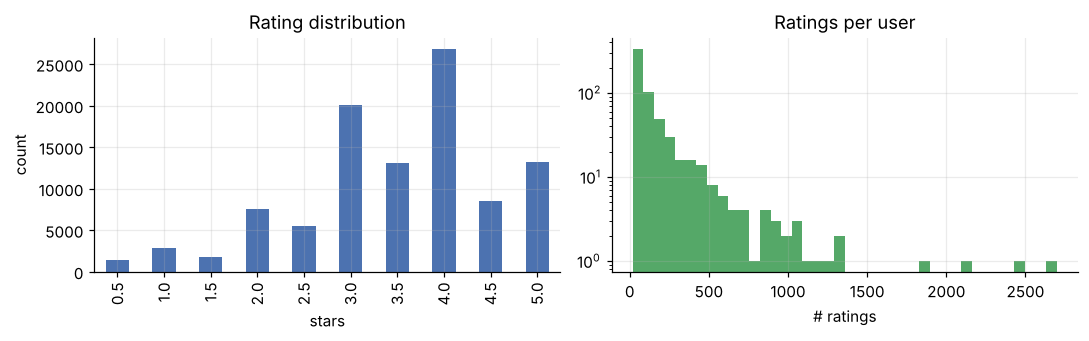

In [3]:
# Integer indices: u in [0, n_users), i in [0, n_items). The CATALOG is every movie in movies.csv (so unrated movies are part of the item space).
user_ids = np.sort(ratings.userId.unique())
item_ids = np.sort(movies.movieId.unique())
n_users, n_items = len(user_ids), len(item_ids)
user_index = pd.Index(user_ids); item_index = pd.Index(item_ids)
ratings["u"] = user_index.get_indexer(ratings.userId)
ratings["i"] = item_index.get_indexer(ratings.movieId)
assert (ratings.i >= 0).all(), "ratings.csv contains movies missing from movies.csv"
movies = movies.set_index("movieId").loc[item_ids].reset_index()

per_user = ratings.groupby("u").size()
sparsity = 1 - len(ratings) / (n_users * n_items)
print(f"users={n_users:,}  items={n_items:,}  ratings={len(ratings):,}  sparsity={sparsity:.2%}")
print(f"ratings/user: min={per_user.min()}  median={per_user.median():.0f}  mean={per_user.mean():.1f}  max={per_user.max()}")
print(f"share of ratings >= {RELEVANT_THRESHOLD:g} stars: {(ratings.rating >= RELEVANT_THRESHOLD).mean():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#4c72b0"); ax[0].set(title="Rating distribution", xlabel="stars", ylabel="count")
ax[1].hist(per_user, bins=40, color="#55a868"); ax[1].set(title="Ratings per user", xlabel="# ratings", yscale="log")
plt.tight_layout(); plt.show()

### 0.2 Rebuilding the Task 11 / Task 12 models (self-contained)

Three recommenders are used throughout:

1. **Matrix factorization (Task 12)** — biased MF, `r̂(u,i) = μ + b_u + b_i + p_u·q_i`, trained with *alternating least squares* (ALS with weighted-λ regularisation).
   ALS is used instead of SGD because each update is an exact ridge-regression solve, which also gives a clean **fold-in** operation for brand-new users (Phase 6).
   With weighted-λ regularisation an item with a single 5-star rating gets an almost un-shrunk bias, and such obscure items then flood the top of every ranking. The standard remedy is a **damped item bias**
   (a constant penalty `λ_b·b_i²` that does not grow with the number of ratings, as in the classic "damped baseline" predictors): items with few ratings are pulled toward the global mean, items with many ratings are barely affected.
   `λ_b` is a hyper-parameter tuned together with `k` and `reg` in Phase 1 (λ_b = 0 switches the damping off).
2. **Content-based (Task 11)** — item vectors = TF-IDF-weighted genres + release decade; a user profile is the rating-weighted average of the vectors of items they liked; score = cosine(profile, item).
3. **Popularity baseline** — rank unseen items by how many training users rated them.

In [4]:
# ---------- Item feature vectors (Task 11 style) ----------
class ItemFeaturizer:
    """Genres (TF-IDF weighted) + release decade (one-hot, down-weighted), L2-normalised per item."""
    def __init__(self, decade_weight=0.5):
        self.decade_weight = decade_weight
    @staticmethod
    def _genres(s):
        return [g for g in str(s).split("|") if g and g != "(no genres listed)"]
    @staticmethod
    def _decade(title):
        m = re.search(r"\((\d{4})\)\s*$", str(title))
        return (int(m.group(1)) // 10) * 10 if m else None
    def fit(self, movies_df):
        gl = movies_df.genres.map(self._genres)
        self.vocab_ = sorted({g for l in gl for g in l})
        self.gidx_ = {g: j for j, g in enumerate(self.vocab_)}
        df_g = np.zeros(len(self.vocab_))
        for l in gl:
            for g in l: df_g[self.gidx_[g]] += 1
        self.idf_ = np.log((1 + len(movies_df)) / (1 + df_g)) + 1.0
        decs = sorted({d for d in movies_df.title.map(self._decade) if d is not None})
        self.decades_ = decs; self.didx_ = {d: j for j, d in enumerate(decs)}
        return self
    def transform(self, movies_df):
        n = len(movies_df)
        X = np.zeros((n, len(self.vocab_) + len(self.decades_)), dtype=np.float32)
        for r, (g, t) in enumerate(zip(movies_df.genres, movies_df.title)):
            for name in self._genres(g):
                if name in self.gidx_: X[r, self.gidx_[name]] = self.idf_[self.gidx_[name]]
            d = self._decade(t)
            if d in self.didx_: X[r, len(self.vocab_) + self.didx_[d]] = self.decade_weight
        nrm = np.linalg.norm(X, axis=1, keepdims=True)
        return X / np.maximum(nrm, 1e-12)

featurizer = ItemFeaturizer().fit(movies)
F = featurizer.transform(movies)          # (n_items, d) L2-normalised item feature matrix  -> used for content model AND diversity
print("item feature matrix:", F.shape, "| genres:", len(featurizer.vocab_), "| decades:", len(featurizer.decades_))

item feature matrix: (9742, 44) | genres: 19 | decades: 25


In [5]:
# ---------- Rating-prediction metrics ----------
def rmse(pred, actual):
    pred, actual = np.asarray(pred, float), np.asarray(actual, float)
    return float(np.sqrt(np.mean((pred - actual) ** 2)))

def mae(pred, actual):
    pred, actual = np.asarray(pred, float), np.asarray(actual, float)
    return float(np.mean(np.abs(pred - actual)))

# ---------- Biased matrix factorization trained with ALS ----------
def _csr(df, n_rows, n_cols, rows="u", cols="i"):
    return sp.csr_matrix((df.rating.values.astype(np.float64), (df[rows].values, df[cols].values)), shape=(n_rows, n_cols))

def _ridge_rows(other, other_bias, mu, indptr, indices, data, reg, k, bias_damp=0.0):
    """For every row r solve [b_r, f_r] = argmin sum (y - b - f.other)^2 + reg*n_r*(b^2 + |f|^2) + bias_damp*b^2   (ALS-WR + damped bias)."""
    n = len(indptr) - 1
    bias, fac = np.zeros(n), np.zeros((n, k))
    for r in range(n):
        lo, hi = indptr[r], indptr[r + 1]
        if hi == lo: continue
        idx = indices[lo:hi]
        X = np.empty((hi - lo, k + 1)); X[:, 0] = 1.0; X[:, 1:] = other[idx]
        y = data[lo:hi] - mu - other_bias[idx]
        A = X.T @ X + reg * (hi - lo) * np.eye(k + 1)
        A[0, 0] += bias_damp                                   # constant (not n-scaled) penalty: rows with few ratings get a strongly shrunk bias
        sol = np.linalg.solve(A, X.T @ y)
        bias[r], fac[r] = sol[0], sol[1:]
    return bias, fac

class BiasALS:
    """r_hat(u,i) = mu + b_u + b_i + p_u . q_i   (Task 12 biased matrix factorization)."""
    def __init__(self, k=32, reg=0.1, iters=12, item_bias_damping=0.0, seed=SEED):
        self.k, self.reg, self.iters, self.item_bias_damping, self.seed = k, reg, iters, item_bias_damping, seed
    def fit(self, train, n_users, n_items):
        rs = np.random.default_rng(self.seed)
        self.n_users, self.n_items = n_users, n_items
        self.mu = float(train.rating.mean())
        R_u, R_i = _csr(train, n_users, n_items), _csr(train, n_users, n_items).T.tocsr()
        self.user_known = np.diff(R_u.indptr) > 0
        self.item_known = np.diff(R_i.indptr) > 0
        self.P = rs.normal(0, 0.1, (n_users, self.k)); self.Q = rs.normal(0, 0.1, (n_items, self.k))
        self.bu, self.bi = np.zeros(n_users), np.zeros(n_items)
        self.history_ = []
        for it in range(self.iters):
            self.bu, self.P = _ridge_rows(self.Q, self.bi, self.mu, R_u.indptr, R_u.indices, R_u.data, self.reg, self.k)
            self.bi, self.Q = _ridge_rows(self.P, self.bu, self.mu, R_i.indptr, R_i.indices, R_i.data, self.reg, self.k, self.item_bias_damping)
            self.history_.append(rmse(self.predict_pairs(train.u.values, train.i.values), train.rating.values))
        return self
    def predict_pairs(self, u, i, clip=True):
        """Unknown users / items have zero bias and zero factors, so they fall back to mu (+ the known side's bias)."""
        p = self.mu + self.bu[u] + self.bi[i] + np.einsum("nk,nk->n", self.P[u], self.Q[i])
        return np.clip(p, 0.5, 5.0) if clip else p
    def score_matrix(self, P=None, bu=None):
        """(n_users, n_items) scores; items with no training ratings cannot be scored -> -inf."""
        P = self.P if P is None else P; bu = self.bu if bu is None else bu
        S = self.mu + bu[:, None] + self.bi[None, :] + P @ self.Q.T
        S[:, ~self.item_known] = -np.inf
        return S
    def fold_in(self, hist):
        """Fit ONLY a user's bias/factors from their history while the item side stays frozen (how a new user is served without retraining)."""
        R = _csr(hist, self.n_users, self.n_items)
        bu, P = _ridge_rows(self.Q, self.bi, self.mu, R.indptr, R.indices, R.data, self.reg, self.k)
        return bu, P

# ---------- Content-based model ----------
def interest_weights(train, n_users, n_items):
    """Sparse user x item weights: max(rating - 2.5, 0); if a user has no item above 2.5 stars every item they rated counts equally."""
    w = np.maximum(train.rating.values - 2.5, 0.0)
    tot = np.bincount(train.u.values, weights=w, minlength=n_users)
    w = np.where(tot[train.u.values] > 0, w, 1.0)
    return sp.csr_matrix((w, (train.u.values, train.i.values)), shape=(n_users, n_items))

def popularity_counts(train, n_items):
    return np.bincount(train.i.values, minlength=n_items).astype(np.float64)

def content_scores(train, F, n_users, n_items):
    """cosine(user profile, item vector); ties are broken by training popularity (1e-6 scale) so equal-vector items are not ordered by item id."""
    W = interest_weights(train, n_users, n_items)
    prof = W @ F
    prof = prof / np.maximum(np.linalg.norm(prof, axis=1, keepdims=True), 1e-12)
    S = prof @ F.T
    cnt = popularity_counts(train, n_items)
    return S + 1e-6 * cnt / max(cnt.max(), 1.0)

def popularity_scores(train, n_users, n_items):
    """Same row for every user: training popularity; exact ties are broken by item index so the ranking is deterministic."""
    base = popularity_counts(train, n_items) + 1e-9 * (1.0 - np.arange(n_items) / n_items)
    return np.tile(base, (n_users, 1))
print("model classes defined: ItemFeaturizer, BiasALS, content_scores, popularity_scores")

model classes defined: ItemFeaturizer, BiasALS, content_scores, popularity_scores


---
## Phase 1 — Splitting Data for Recommender Evaluation

### 1.1 Why a naive random row split is subtly wrong

`train_test_split(ratings)` shuffles *rows*. For a recommender that means a user's **later** ratings can land in train while their **earlier** ones land in test:
the model gets to learn from the user's future (and from the whole community's future tastes) and is then asked to "predict" the past. That is information leakage — nothing
in production can do this, because at serving time you only ever know what has already happened. Random splits also mix in time-local effects (a film everybody rated the week
it was added to the site), which makes held-out ratings easier to guess than genuinely future ratings. The result is a **silently inflated** metric.

Three splits that respect the structure of the problem:

| Split | Rule | Typical use |
|---|---|---|
| **Temporal (per user)** | each user's earliest 80 % of ratings (by `timestamp`) → train, latest 20 % → test | the most **realistic** simulation of production: train on the past, test on the future |
| **Leave-one-out** | each user's single most recent interaction → test, everything else → train | the most common in **academic papers** (simple, every user is tested exactly once) |
| **Per-user random holdout** | a random 20 % of each user's ratings → test | keeps every user in both sets, but ignores time, so it still leaks |

In [6]:
def _tail_split(d, n_test):
    """d is sorted by the intended order within each user; the last n_test[u] rows of each user go to test."""
    pos = d.groupby("u").cumcount().values
    n = d.groupby("u")["i"].transform("size").values
    is_test = pos >= (n - n_test)
    return d[~is_test].copy(), d[is_test].copy()

def _n_test(d, frac=None, fixed=None):
    n = d.groupby("u")["i"].transform("size").values
    k = np.full(len(d), fixed) if fixed is not None else np.rint(frac * n).astype(int)
    return np.minimum(np.maximum(k, 1), n - 1)          # >=1 test row and >=1 train row per user

def temporal_split(df, test_frac=0.2):
    """Per user: earliest (1-test_frac) of ratings by timestamp -> train, most recent test_frac -> test."""
    d = df.sort_values(["u", "timestamp", "i"], kind="mergesort")
    return _tail_split(d, _n_test(d, frac=test_frac))

def leave_one_out_split(df):
    """Per user: the single most recent interaction -> test."""
    d = df.sort_values(["u", "timestamp", "i"], kind="mergesort")
    return _tail_split(d, _n_test(d, fixed=1))

def per_user_holdout_split(df, test_frac=0.2, seed=SEED):
    """Per user: a RANDOM test_frac of their ratings -> test (time ignored). Every user appears in both sets."""
    d = df.copy()
    d["_r"] = np.random.default_rng(seed).random(len(d))
    d = d.sort_values(["u", "_r"], kind="mergesort")
    tr, te = _tail_split(d, _n_test(d, frac=test_frac))
    return tr.drop(columns="_r"), te.drop(columns="_r")

def naive_random_split(df, test_frac=0.2, seed=SEED):
    """The split to AVOID: shuffle rows globally, ignoring users and time."""
    te_mask = np.random.default_rng(seed).random(len(df)) < test_frac
    return df[~te_mask].copy(), df[te_mask].copy()

SPLITS = {
    "naive random rows":        naive_random_split(ratings),
    "temporal (per user 80/20)": temporal_split(ratings),
    "leave-one-out":            leave_one_out_split(ratings),
    "per-user random 20%":      per_user_holdout_split(ratings),
}
train_t, test_t = SPLITS["temporal (per user 80/20)"]       # the split used for the rest of the notebook
print({k: (len(a), len(b)) for k, (a, b) in SPLITS.items()})

{'naive random rows': (80779, 20057), 'temporal (per user 80/20)': (80672, 20164), 'leave-one-out': (100226, 610), 'per-user random 20%': (80672, 20164)}


In [7]:
def split_report(name, tr, te, full=ratings):
    last_train_ts = tr.groupby("u").timestamp.max()
    leak = (te.timestamp.values < last_train_ts.reindex(te.u.values).values)          # test rating happened BEFORE some training rating of the same user
    seen_items = np.zeros(n_items, bool); seen_items[tr.i.values] = True
    return {"split": name, "train rows": len(tr), "test rows": len(te), "test share": len(te) / (len(tr) + len(te)),
            "users in train": tr.u.nunique(), "users in test": te.u.nunique(),
            "test rows/user": len(te) / te.u.nunique(),
            "test rows w/ later train row (same user)": float(np.nanmean(leak)),
            "test items unseen in train": float((~seen_items[te.i.values]).mean())}

split_table = pd.DataFrame([split_report(k, a, b) for k, (a, b) in SPLITS.items()]).set_index("split")
display(split_table.style.format({"train rows": "{:,.0f}", "test rows": "{:,.0f}", "users in train": "{:,.0f}", "users in test": "{:,.0f}",
                                  "test share": "{:.1%}", "test rows/user": "{:.2f}",
                                  "test rows w/ later train row (same user)": "{:.1%}", "test items unseen in train": "{:.1%}"}))

# ---- integrity checks (these would raise if a split were wrong) ----
for name, (tr, te) in SPLITS.items():
    assert not set(zip(tr.u, tr.i)) & set(zip(te.u, te.i)), f"{name}: a (user,item) pair is in both train and test"
    assert len(tr) + len(te) == len(ratings), f"{name}: rows lost"
for name in ["temporal (per user 80/20)", "leave-one-out", "per-user random 20%"]:
    tr, te = SPLITS[name]
    assert set(te.u) <= set(tr.u) and tr.u.nunique() == n_users, f"{name}: a user is missing from train/test"
tr, te = SPLITS["temporal (per user 80/20)"]
assert (te.groupby("u").timestamp.min() >= tr.groupby("u").timestamp.max()).all(), "temporal split leaks the future"
assert len(SPLITS["leave-one-out"][1]) == n_users
print("split integrity checks passed")

,train rows,test rows,test share,users in train,users in test,test rows/user,test rows w/ later train row (same user),test items unseen in train
split,,,,,,,,
naive random rows,"80,779","20,057",19.9%,610,609,32.93,98.9%,4.1%
temporal (per user 80/20),"80,672","20,164",20.0%,610,610,33.06,0.0%,8.4%
leave-one-out,"100,226",610,0.6%,610,610,1.00,0.0%,3.8%
per-user random 20%,"80,672","20,164",20.0%,610,610,33.06,98.9%,4.1%


split integrity checks passed


### 1.2 Written comparison of the splits

* **Sizes.** The temporal and per-user splits use the same 80/20 ratio per user, so their train/test sizes are almost identical; the *naive random* split has the same overall ratio
  but not a per-user one (a light user can lose most of their ratings to test). **Leave-one-out** puts exactly one row per user in test, so its test set is tiny
  (`n_users` rows) — cheap to evaluate, but statistically noisy for RMSE and only measures how well the *very next* item is predicted.
* **Leakage.** The column *"test rows w/ later train row (same user)"* is the direct measurement of the leak described above: for the naive random and the per-user random splits a large share of
  test ratings happened *before* something the model trained on; for the temporal and leave-one-out splits it is 0 % by construction.
* **Cold items.** Because time moves forward, the temporal test set contains items that did not exist (or were unrated) in the training period — exactly what production faces, and a first hint of the cold-start problem in Phase 6.
* **Which to use.** Temporal is the most realistic simulation of production; leave-one-out is the paper default because it is simple and every user is tested once; the two random splits are fine for quick debugging and nothing else.

### 1.3 Choosing MF hyper-parameters (on validation data only)

Before comparing splits we need a sensible Task 12 style MF model. Hyper-parameters (number of factors `k`, regularisation `reg`, and the item-bias damping `λ_b` described in 0.2) are picked by **validation RMSE** on an **inner temporal validation split** carved from the *training* part of the temporal split,
so the temporal test set is never touched during tuning.

In [8]:
inner_train, valid = temporal_split(train_t)                    # train_t = past of the past, valid = recent part of train_t
grid = [(k, reg, damp) for k in (16, 32) for reg in (0.05, 0.1, 0.2, 0.4) for damp in (0, 10, 25)]
rows, models_grid = [], {}
t = time.time()
for k, reg, damp in grid:
    m = BiasALS(k=k, reg=reg, iters=10, item_bias_damping=damp).fit(inner_train, n_users, n_items)
    models_grid[(k, reg, damp)] = m
    rows.append({"k": k, "reg": reg, "item bias damping": damp, "train RMSE": m.history_[-1],
                 "valid RMSE": rmse(m.predict_pairs(valid.u.values, valid.i.values), valid.rating.values),
                 "valid MAE": mae(m.predict_pairs(valid.u.values, valid.i.values), valid.rating.values)})
grid_df = pd.DataFrame(rows).sort_values("valid RMSE").reset_index(drop=True)
display(grid_df.head(10))
BEST = dict(k=int(grid_df.loc[0, "k"]), reg=float(grid_df.loc[0, "reg"]), item_bias_damping=float(grid_df.loc[0, "item bias damping"]), iters=12)
mf_inner = models_grid[(BEST["k"], BEST["reg"], int(BEST["item_bias_damping"]))]   # fitted on inner_train; reused for the alpha sweep in Phase 7
print(f"chosen hyper-parameters: {BEST}   ({time.time()-t:.0f}s)")
if BEST["reg"] in (min(g[1] for g in grid), max(g[1] for g in grid)) or BEST["item_bias_damping"] in (min(g[2] for g in grid), max(g[2] for g in grid)):
    print("NOTE: a chosen value sits on the edge of the grid - widen the grid if you want a fully tuned model.")

,k,reg,item bias damping,train RMSE,valid RMSE,valid MAE
0,32,0.2000,10,0.6756,0.8791,0.6761
1,32,0.2000,25,0.6778,0.8797,0.6771
2,32,0.2000,0,0.6836,0.8800,0.6770
3,32,0.1000,0,0.4623,0.8801,0.6761
4,16,0.2000,10,0.6821,0.8803,0.6763
5,16,0.2000,25,0.6844,0.8809,0.6774
6,16,0.2000,0,0.6895,0.8819,0.6783
7,32,0.1000,25,0.4597,0.8862,0.6802
8,16,0.1000,0,0.5039,0.8871,0.6792
9,32,0.1000,10,0.4585,0.8873,0.6808


chosen hyper-parameters: {'k': 32, 'reg': 0.2, 'item_bias_damping': 10.0, 'iters': 12}   (60s)


### 1.4 Fit the same MF model on every split and compare RMSE

Same model, same hyper-parameters, four different train/test protocols. The only thing that changes is **how the held-out ratings are chosen**.
Users/items that do not appear in training fall back to the global mean (+ the bias of the side that *is* known).

> The Task 12 notebook is not available inside this environment, so its original (random) split is represented by the **naive random row split** here — that is the split the README assumes Task 12 used.

In [9]:
split_models, rows = {}, []
t = time.time()
for name, (tr, te) in SPLITS.items():
    m = BiasALS(**BEST).fit(tr, n_users, n_items)
    split_models[name] = m
    pred = m.predict_pairs(te.u.values, te.i.values)
    unseen_item = ~m.item_known[te.i.values]
    rows.append({"split": name, "train rows": len(tr), "test rows": len(te),
                 "RMSE": rmse(pred, te.rating.values), "MAE": mae(pred, te.rating.values),
                 "test rows w/ unseen item": unseen_item.mean()})
rmse_by_split = pd.DataFrame(rows).set_index("split")
display(rmse_by_split.style.format({"train rows": "{:,.0f}", "test rows": "{:,.0f}", "RMSE": "{:.4f}", "MAE": "{:.4f}", "test rows w/ unseen item": "{:.1%}"}))
print(f"fitted 4 models in {time.time()-t:.0f}s")

r_naive = rmse_by_split.loc["naive random rows", "RMSE"]; r_temp = rmse_by_split.loc["temporal (per user 80/20)", "RMSE"]
RESULTS["rmse_naive"], RESULTS["rmse_temporal"] = r_naive, r_temp
word = "HIGHER (worse)" if r_temp > r_naive else "LOWER (better)"
print(f"\nRMSE naive random split : {r_naive:.4f}\nRMSE temporal split     : {r_temp:.4f}   -> temporal is {word} by {abs(r_temp - r_naive):.4f} "
      f"({abs(r_temp - r_naive) / r_naive:+.1%} relative)")

,train rows,test rows,RMSE,MAE,test rows w/ unseen item
split,,,,,
naive random rows,"80,779","20,057",0.8593,0.6601,4.1%
temporal (per user 80/20),"80,672","20,164",0.8984,0.6897,8.4%
leave-one-out,"100,226",610,0.9558,0.7424,3.8%
per-user random 20%,"80,672","20,164",0.8624,0.6617,4.1%


fitted 4 models in 17s

RMSE naive random split : 0.8593
RMSE temporal split     : 0.8984   -> temporal is HIGHER (worse) by 0.0391 (+4.6% relative)


**Reading the table.** The usual outcome on MovieLens is that the temporal RMSE is *worse* than the naive-random RMSE: the random split lets the model see the user's later taste and
the community's contemporaneous ratings, while the temporal split asks it to extrapolate into a future it has not seen (and into movies it has never seen rated). The gap is the size of the optimism a
random split bakes into every number you report — if you quote the random-split RMSE as your production expectation, you will be disappointed. (The line printed above states the sign and size of the gap actually measured in this run.)
Leave-one-out RMSE is computed on just one row per user, so treat its decimals with suspicion — it has the highest sampling noise of the four.

The temporal split is used for everything from here on.

---
## Phase 2 — Predictive Metrics: RMSE & MAE

$$\text{RMSE}=\sqrt{\tfrac1N\sum_{(u,i)\in\text{test}}(\hat r_{ui}-r_{ui})^2}\qquad\qquad \text{MAE}=\tfrac1N\sum_{(u,i)\in\text{test}}\lvert\hat r_{ui}-r_{ui}\rvert$$

RMSE squares the error, so it punishes a few big mistakes harder than MAE; MAE is the more literal "on average we are off by x stars". Both are computed below for the Task 12 matrix-factorization
model on the **temporal test split** from Phase 1, next to two trivial reference predictors so the numbers have a scale.

In [10]:
mf = split_models["temporal (per user 80/20)"]          # the "Task 12" MF model: fitted on the temporal training data
u_te, i_te, y_te = test_t.u.values, test_t.i.values, test_t.rating.values

pred_mf = mf.predict_pairs(u_te, i_te)
pred_global = np.full(len(y_te), train_t.rating.mean())
um = train_t.groupby("u").rating.mean().reindex(range(n_users)).fillna(train_t.rating.mean()).values
pred_usermean = um[u_te]

phase2 = pd.DataFrame({"RMSE": [rmse(p, y_te) for p in (pred_mf, pred_usermean, pred_global)],
                       "MAE":  [mae(p, y_te)  for p in (pred_mf, pred_usermean, pred_global)]},
                      index=["Matrix factorization (Task 12 model)", "User-mean baseline", "Global-mean baseline"])
display(phase2)
RESULTS["rmse_mf"], RESULTS["mae_mf"] = float(phase2.iloc[0, 0]), float(phase2.iloc[0, 1])
print(f"MF on the temporal test split: RMSE = {RESULTS['rmse_mf']:.4f}, MAE = {RESULTS['mae_mf']:.4f}  ({len(y_te):,} test ratings)")

# Where does the squared error come from? RMSE weights every rating equally, regardless of whether the item would ever be shown.
err = pd.DataFrame({"actual": y_te, "sq_err": (pred_mf - y_te) ** 2})
by_rating = err.groupby("actual").sq_err.agg(["count", "mean"]).rename(columns={"count": "n test ratings", "mean": "mean squared error"})
by_rating["share of all squared error"] = err.groupby("actual").sq_err.sum() / err.sq_err.sum()
display(by_rating.style.format({"n test ratings": "{:,.0f}", "mean squared error": "{:.3f}", "share of all squared error": "{:.1%}"}))
low_share = float(err.loc[err.actual < 3, "sq_err"].sum() / err.sq_err.sum()); low_n = float((err.actual < 3).mean())
print(f"ratings below 3 stars are {low_n:.1%} of the test ratings but {low_share:.1%} of the total squared error - error on items that a top-10 list would almost never show.")

,RMSE,MAE
Matrix factorization (Task 12 model),0.8984,0.6897
User-mean baseline,0.9665,0.7498
Global-mean baseline,1.0693,0.8367


MF on the temporal test split: RMSE = 0.8984, MAE = 0.6897  (20,164 test ratings)


,n test ratings,mean squared error,share of all squared error
actual,,,
0.500000,371,5.805,13.2%
1.000000,637,4.557,17.8%
1.500000,438,2.468,6.6%
2.000000,"1,549",1.463,13.9%
2.500000,"1,095",0.670,4.5%
3.000000,"3,805",0.296,6.9%
3.500000,"2,911",0.106,1.9%
4.000000,"5,168",0.237,7.5%
4.500000,"1,839",0.682,7.7%


ratings below 3 stars are 20.3% of the test ratings but 56.2% of the total squared error - error on items that a top-10 list would almost never show.


### 2.1 When RMSE / MAE are — and are not — the right metric

**The core limitation for recommendation.** RMSE and MAE charge every rating error the same price, but a user never sees a predicted rating for every item — they see a **top-10 list**.
The table above and the line printed under it show the problem: a large share of the squared error is spent on mediocre/low ratings (items that would rarely be shown to the user anyway) while the few items at the very top of the
ranking — the only ones that matter — are a small slice of the sum. A model can therefore have an excellent RMSE and still put garbage in the top 10 (it is accurate on the "obviously 1-star" items nobody will ever see),
and two models with almost the same RMSE can rank very differently. Phase 4 demonstrates this on real numbers.

**When they are still the right choice.** When the product surface *is* a predicted rating or score — "we predict you'd rate this 4.2 stars", a score shown on a title page,
a rating-prediction competition, or a regression sub-component that feeds a later ranking stage. In those cases the size of the error in stars is the thing the user actually experiences.

**When they are the wrong choice.** When the product is a ranked list/carousel (the usual case), when feedback is implicit (clicks, watches — there is no star to be wrong about), and when the catalog is
long-tailed enough that most predictions are never displayed. Use the ranking metrics of Phases 3–4 instead, and treat RMSE/MAE as a diagnostic.

---
## Phase 3 — Precision@K, Recall@K & F1@K

With `R_K` = the user's top-K list and `Rel` = the user's relevant held-out items:

$$\text{Precision@K}=\frac{|R_K\cap Rel|}{K}\qquad \text{Recall@K}=\frac{|R_K\cap Rel|}{|Rel|}\qquad \text{F1@K}=\frac{2\cdot P@K\cdot R@K}{P@K+R@K}$$

* **Precision@K** answers *"of what I showed, how much was relevant?"*
* **Recall@K** answers *"of what is relevant, how much did I show?"*
* **F1@K** is their harmonic mean (it is high only if both are).

### 3.1 What counts as "relevant"

A held-out item is **relevant if the user rated it ≥ 4 stars** (`RELEVANT_THRESHOLD`). Held-out items rated lower are *not* relevant (the user saw them and was lukewarm), and items with no
held-out rating are treated as non-relevant too (the standard, slightly pessimistic, closed-world assumption: "unrated" ≠ "disliked", but we have no evidence they are liked).
Users with **no** relevant held-out item cannot score on Precision/Recall (the denominator of Recall would be 0), so they are excluded from every ranking metric — the same user set is used for every metric and every model below.

**Ranking protocol.** For each user the model scores *every catalog item the user did not rate in the training data*; the top-K of that full ranking is the recommendation list.

In [11]:
class Evaluator:
    """Ranking evaluation against a fixed (train, test) pair. Scores are (n_users, n_items) matrices; train items are masked out before ranking."""
    def __init__(self, train, test, thresh=RELEVANT_THRESHOLD, kmax=max(KS), users=None):
        self.thresh, self.kmax = thresh, kmax
        self.seen = np.zeros((n_users, n_items), bool);  self.seen[train.u.values, train.i.values] = True
        self.T = np.zeros((n_users, n_items), np.float32); self.T[test.u.values, test.i.values] = test.rating.values
        self.rel = self.T >= thresh                                    # binary relevance
        self.n_rel = self.rel.sum(1)
        self.users = np.where(self.n_rel > 0)[0]                       # eligible users (>= 1 relevant held-out item)
        if users is not None: self.users = np.intersect1d(self.users, users)   # optionally restrict to a cohort
        self.ideal = -np.sort(-self.T[self.users], axis=1)[:, :kmax]   # held-out ratings, best first (for IDCG)
        self.train_pop = popularity_counts(train, n_items)
    def topk(self, S, k=None):
        k = k or self.kmax
        S = np.where(self.seen, -np.inf, S)[self.users]
        part = np.argpartition(-S, k - 1, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(S, part, 1), axis=1, kind="stable")
        return np.take_along_axis(part, order, 1)                      # (n_eligible, k) item indices, best first
    def metrics(self, S=None, ks=KS, top=None):
        """Per-user metrics (DataFrame indexed by user index). Pass either a score matrix S or a precomputed top-k matrix."""
        top = self.topk(S) if top is None else top
        rel, T, nrel = self.rel[self.users], self.T[self.users], self.n_rel[self.users]
        out = {}
        for K in ks:
            tk = top[:, :K]
            hits = np.take_along_axis(rel, tk, 1)
            nh = hits.sum(1)
            P, R = nh / K, nh / nrel
            out[f"P@{K}"], out[f"R@{K}"] = P, R
            out[f"F1@{K}"] = np.divide(2 * P * R, P + R, out=np.zeros_like(P), where=(P + R) > 0)
            prec_n = np.cumsum(hits, 1) / np.arange(1, K + 1)
            out[f"AP@{K}"] = (prec_n * hits).sum(1) / np.minimum(K, nrel)
            disc = 1.0 / np.log2(np.arange(2, K + 2))
            dcg = ((2.0 ** np.take_along_axis(T, tk, 1) - 1) * disc).sum(1)
            idcg = ((2.0 ** self.ideal[:, :K] - 1) * disc).sum(1)
            out[f"NDCG@{K}"] = dcg / idcg
            dcg_b = (hits * disc).sum(1); idcg_b = np.array([disc[:min(K, n)].sum() for n in nrel])
            out[f"NDCGbin@{K}"] = dcg_b / idcg_b
            first = np.where(hits.any(1), hits.argmax(1) + 1, np.inf)
            out[f"RR@{K}"] = 1.0 / first
        return pd.DataFrame(out, index=self.users)

# ---- independent, loop-based reference implementations (used to verify the vectorised code) ----
def precision_at_k_ref(rec, relevant, k):  return sum(1 for x in rec[:k] if x in relevant) / k
def recall_at_k_ref(rec, relevant, k):     return sum(1 for x in rec[:k] if x in relevant) / len(relevant)
def ap_at_k_ref(rec, relevant, k):
    hits, total = 0, 0.0
    for n, x in enumerate(rec[:k], start=1):
        if x in relevant:
            hits += 1; total += hits / n
    return total / min(k, len(relevant))
def dcg_ref(gains, k):  return sum((2 ** g - 1) / math.log2(i + 1) for i, g in enumerate(gains[:k], start=1))
def ndcg_ref(rec, graded, k):
    ideal = sorted(graded.values(), reverse=True)
    return dcg_ref([graded.get(x, 0) for x in rec], k) / dcg_ref(ideal, k)
def rr_ref(rec, relevant, k):
    for n, x in enumerate(rec[:k], start=1):
        if x in relevant: return 1.0 / n
    return 0.0

ev = Evaluator(train_t, test_t)                       # evaluator for the temporal split
S_mf = mf.score_matrix()                              # (n_users, n_items) MF scores; -inf for items with no training ratings
top_mf = ev.topk(S_mf)
print(f"eligible users (>=1 relevant held-out item): {len(ev.users)} of {n_users}  |  mean relevant held-out items/user: {ev.n_rel[ev.users].mean():.1f}")

eligible users (>=1 relevant held-out item): 592 of 610  |  mean relevant held-out items/user: 15.8


### 3.2 One user by hand (Precision@10 and Recall@10)

To keep the arithmetic informative the demo user is chosen by a fixed rule: among users whose top-10 contains **at least 3** relevant items, the one whose number of relevant held-out items is closest to the median. That guarantees there is something to compute while avoiding an unusually easy or unusually hard user.

In [12]:
hits10 = np.take_along_axis(ev.rel[ev.users], top_mf[:, :10], 1).sum(1)
cands = np.where(hits10 >= 3)[0]
med_rel = np.median(ev.n_rel[ev.users])
pos = int(cands[np.argmin(np.abs(ev.n_rel[ev.users][cands] - med_rel))]) if len(cands) else int(hits10.argmax())   # >=3 hits, typical number of relevant items
demo_u = int(ev.users[pos])
rec_demo = [int(x) for x in top_mf[pos, :10]]
rel_demo = set(np.where(ev.rel[demo_u])[0].tolist())
print(f"demo user: userId={user_ids[demo_u]}  |  training ratings: {int(ev.seen[demo_u].sum())}  |  held-out items: {int((ev.T[demo_u] > 0).sum())}  |  relevant held-out items (>= {RELEVANT_THRESHOLD:g}): {len(rel_demo)}")

tbl = pd.DataFrame({"rank": range(1, 11), "movieId": item_ids[rec_demo],
                    "title": movies.title.values[rec_demo],
                    "held-out rating": [ev.T[demo_u, i] if ev.T[demo_u, i] > 0 else np.nan for i in rec_demo],
                    "relevant?": [int(i in rel_demo) for i in rec_demo]})
display(tbl.style.format({"held-out rating": "{:.1f}"}, na_rep="—"))

n_hit = sum(tbl["relevant?"])
print(f"\nrelevant items in the top-10 : {n_hit}")
print(f"Precision@10 = {n_hit} / 10 = {n_hit/10:.3f}")
print(f"Recall@10    = {n_hit} / {len(rel_demo)} = {n_hit/len(rel_demo):.3f}")
p_, r_ = n_hit / 10, n_hit / len(rel_demo)
print(f"F1@10        = 2*{p_:.3f}*{r_:.3f} / ({p_:.3f}+{r_:.3f}) = {2*p_*r_/(p_+r_) if p_+r_ else 0:.3f}")

m_demo = ev.metrics(top=top_mf).loc[demo_u]
assert abs(m_demo["P@10"] - precision_at_k_ref(rec_demo, rel_demo, 10)) < 1e-12 and abs(m_demo["R@10"] - recall_at_k_ref(rec_demo, rel_demo, 10)) < 1e-12
assert abs(m_demo["P@10"] - n_hit / 10) < 1e-12 and abs(m_demo["R@10"] - n_hit / len(rel_demo)) < 1e-12
print("hand calculation == vectorised implementation  OK")

demo user: userId=585  |  training ratings: 49  |  held-out items: 12  |  relevant held-out items (>= 4): 12


,rank,movieId,title,held-out rating,relevant?
0,1,318,"Shawshank Redemption, The (1994)",—,0
1,2,750,Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964),—,0
2,3,356,Forrest Gump (1994),—,0
3,4,1197,"Princess Bride, The (1987)",—,0
4,5,48516,"Departed, The (2006)",4.5,1
5,6,1193,One Flew Over the Cuckoo's Nest (1975),—,0
6,7,912,Casablanca (1942),—,0
7,8,1213,Goodfellas (1990),5.0,1
8,9,50,"Usual Suspects, The (1995)",—,0
9,10,58559,"Dark Knight, The (2008)",4.0,1



relevant items in the top-10 : 3
Precision@10 = 3 / 10 = 0.300
Recall@10    = 3 / 12 = 0.250
F1@10        = 2*0.300*0.250 / (0.300+0.250) = 0.273


hand calculation == vectorised implementation  OK


### 3.3 Precision, Recall and F1 averaged over all users, K ∈ {5, 10, 20}

,Precision@K,Recall@K,F1@K
K,,,
5,0.0250,0.0109,0.0128
10,0.0258,0.0201,0.0185
20,0.0238,0.0372,0.0235


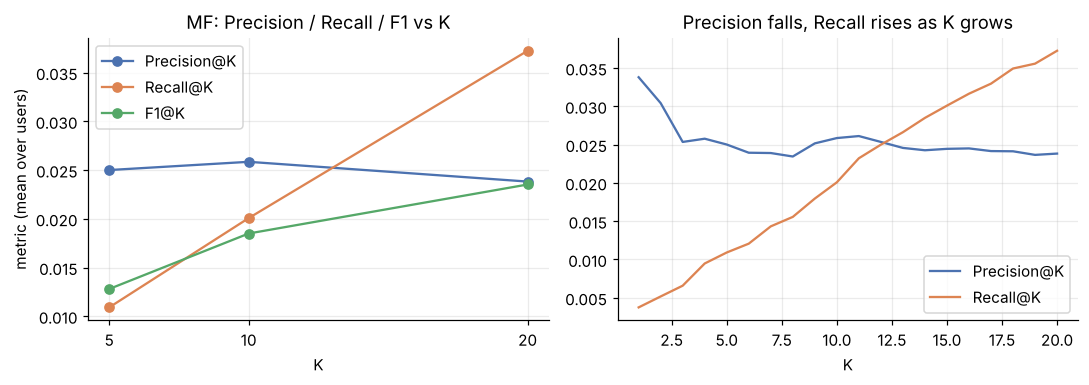

F1@10: mean of per-user F1 = 0.0185   vs   harmonic mean of the averaged P and R = 0.0226


In [13]:
met_mf = ev.metrics(top=top_mf)                           # per-user metrics, eligible users only
tab3 = pd.DataFrame({K: {"Precision@K": met_mf[f"P@{K}"].mean(), "Recall@K": met_mf[f"R@{K}"].mean(), "F1@K": met_mf[f"F1@{K}"].mean()} for K in KS}).T
tab3.index.name = "K"
display(tab3)
RESULTS["pr_table_mf"] = tab3.copy()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for col, c in zip(tab3.columns, ["#4c72b0", "#dd8452", "#55a868"]):
    ax[0].plot(tab3.index, tab3[col], marker="o", label=col, color=c)
ax[0].set(title="MF: Precision / Recall / F1 vs K", xlabel="K", ylabel="metric (mean over users)", xticks=list(KS)); ax[0].legend()
Ks_dense = list(range(1, 21))
mm = ev.metrics(top=top_mf, ks=Ks_dense)
ax[1].plot(Ks_dense, [mm[f"P@{k}"].mean() for k in Ks_dense], label="Precision@K", color="#4c72b0")
ax[1].plot(Ks_dense, [mm[f"R@{k}"].mean() for k in Ks_dense], label="Recall@K", color="#dd8452")
ax[1].set(title="Precision falls, Recall rises as K grows", xlabel="K"); ax[1].legend()
plt.tight_layout(); plt.show()

# per-user vs "F1 of the averages": they are different numbers, the per-user mean is what is reported above
K = 10; pm, rm = tab3.loc[K, "Precision@K"], tab3.loc[K, "Recall@K"]
print(f"F1@10: mean of per-user F1 = {tab3.loc[K, 'F1@K']:.4f}   vs   harmonic mean of the averaged P and R = {2*pm*rm/(pm+rm):.4f}")

**Reading the plot.** As K grows, Recall can only go up (a longer list can only catch more relevant items) while Precision tends to fall (the extra slots are filled with lower-ranked, less likely items).
F1 is the compromise between the two. Absolute values are low in a task like this: the model has to pick a handful of relevant items out of a catalog of thousands, and each user has only a few held-out relevant items — that is normal for top-N recommendation.

### 3.4 The limitation Precision@K and Recall@K share: they are blind to order

Both metrics only count *how many* relevant items are in the top-K — not *where*. A relevant item at rank 1 counts exactly the same as one at rank 10. The next cell makes this concrete.

In [14]:
# Two lists with the SAME 3 relevant items (marked 1): list A puts them at ranks 1-3, list B at ranks 8-10.
A = [1, 1, 1, 0, 0, 0, 0, 0, 0, 0]
B = [0, 0, 0, 0, 0, 0, 0, 1, 1, 1]
def pr_ap(l, total_rel=3, k=10):
    nh = sum(l); prec_n = np.cumsum(l) / np.arange(1, k + 1)
    return nh / k, nh / total_rel, (prec_n * np.array(l)).sum() / min(k, total_rel)
order_demo = pd.DataFrame([pr_ap(A), pr_ap(B)], index=["A: hits at ranks 1,2,3", "B: hits at ranks 8,9,10"], columns=["Precision@10", "Recall@10", "AP@10 (Phase 4)"])
display(order_demo)
assert order_demo["Precision@10"].nunique() == 1 and order_demo["Recall@10"].nunique() == 1 and order_demo["AP@10 (Phase 4)"].nunique() == 2
print("Precision@10 and Recall@10 cannot tell A from B; an order-aware metric (AP/NDCG, Phase 4) can.")

,Precision@10,Recall@10,AP@10 (Phase 4)
"A: hits at ranks 1,2,3",0.3000,1.0000,1.0000
"B: hits at ranks 8,9,10",0.3000,1.0000,0.2157


Precision@10 and Recall@10 cannot tell A from B; an order-aware metric (AP/NDCG, Phase 4) can.


---
## Phase 4 — Ranking Metrics: MAP & NDCG

### 4.1 Average Precision@K and MAP

$$\text{AP@K}=\frac{1}{\min(K,|Rel|)}\sum_{n=1}^{K}\text{Precision@}n\cdot rel(n)\qquad\qquad \text{MAP}=\frac1{|U|}\sum_{u}\text{AP@K}(u)$$

where `rel(n) = 1` if the item at rank `n` is relevant. Only ranks that hold a relevant item contribute a term, and the term is the precision *at that rank*.

**Hand-worked AP@10** for the demo user from Phase 3:

In [15]:
rel_flags = [int(i in rel_demo) for i in rec_demo]
rows, running, terms = [], 0, []
for n, f in enumerate(rel_flags, start=1):
    running += f
    rows.append({"rank n": n, "rel(n)": f, "relevant so far": running, "Precision@n": running / n, "term = P@n * rel(n)": (running / n) * f})
    if f: terms.append((n, running))
ap_tbl = pd.DataFrame(rows).set_index("rank n")
display(ap_tbl)

denom = min(10, len(rel_demo))
ap_hand = sum(h / n for n, h in terms) / denom
print("relevant items sit at ranks:", [n for n, _ in terms])
print("AP@10 = (1 / min(10, |Rel|=%d)) * (%s)" % (len(rel_demo), " + ".join(f"{h}/{n}" for n, h in terms) or "0"))
print("      = (1 / %d) * (%s)" % (denom, " + ".join(f"{h/n:.4f}" for n, h in terms) or "0"))
print(f"      = {ap_hand:.4f}")
assert abs(ap_hand - ap_at_k_ref(rec_demo, rel_demo, 10)) < 1e-12 and abs(ap_hand - met_mf.loc[demo_u, "AP@10"]) < 1e-12
print("hand calculation == loop reference == vectorised implementation  OK")

,rel(n),relevant so far,Precision@n,term = P@n * rel(n)
rank n,,,,
1,0,0,0.0000,0.0000
2,0,0,0.0000,0.0000
3,0,0,0.0000,0.0000
4,0,0,0.0000,0.0000
5,1,1,0.2000,0.2000
6,0,1,0.1667,0.0000
7,0,1,0.1429,0.0000
8,1,2,0.2500,0.2500
9,0,2,0.2222,0.0000


relevant items sit at ranks: [5, 8, 10]
AP@10 = (1 / min(10, |Rel|=12)) * (1/5 + 2/8 + 3/10)
      = (1 / 10) * (0.2000 + 0.2500 + 0.3000)
      = 0.0750
hand calculation == loop reference == vectorised implementation  OK


**Why MAP rewards putting relevant items earlier.** A relevant item at rank 1 contributes `Precision@1 = 1.0` to the sum; the *same* item at rank 10 contributes at most `Precision@10 = 0.1`.
Every relevant item that is pushed down the list also drags down the precision terms of all relevant items that come after it, so order matters — unlike Precision@K / Recall@K in Phase 3.

In [16]:
print("a single relevant item at rank n (and |Rel| = 1):")
display(pd.DataFrame({"rank of the hit": [1, 2, 3, 5, 10], "AP@10": [ap_at_k_ref([0]*(n-1) + [99], {99}, 10) for n in [1, 2, 3, 5, 10]]}).set_index("rank of the hit").T)

a single relevant item at rank n (and |Rel| = 1):


rank of the hit,1,2,3,5,10
AP@10,1.0000,0.5000,0.3333,0.2000,0.1000


### 4.2 DCG and NDCG (graded relevance)

$$\text{DCG@K}=\sum_{i=1}^{K}\frac{2^{rel_i}-1}{\log_2(i+1)}\qquad\qquad \text{NDCG@K}=\frac{\text{DCG@K}}{\text{IDCG@K}}\in[0,1]$$

* The **gain** `2^rel − 1` makes a 5-star item far more valuable than a 3-star one (31 vs 7), instead of treating them alike.
* The **discount** `1 / log2(i+1)` shrinks the value of a hit as it slides down the list: rank 1 → 1.00, rank 2 → 0.63, rank 3 → 0.50, rank 10 → 0.29. The log makes the first few positions dominate, which matches how users read lists.
* **IDCG@K** is the DCG of the *ideal* ordering of that user's held-out items (best rating first), so a perfect list scores exactly 1 and scores are comparable across users who have different numbers/qualities of relevant items.

Here `rel_i` is the **user's actual held-out star rating** of the item at rank `i` (0 if the user has no held-out rating for it). This is why NDCG, unlike MAP, naturally supports graded relevance: MAP can only ask "relevant or not", whereas NDCG can also tell a list full of 5-star items from one full of 4.0s.

**Hand-worked NDCG@10** for the same demo user:

In [17]:
g_rec = [float(ev.T[demo_u, i]) for i in rec_demo]                          # actual held-out rating of each recommended item (0 = none)
disc = [1 / math.log2(i + 1) for i in range(1, 11)]
dcg_tbl = pd.DataFrame({"rank i": range(1, 11), "rel_i (rating)": g_rec, "gain 2^rel - 1": [2 ** g - 1 for g in g_rec],
                        "discount 1/log2(i+1)": disc, "contribution": [(2 ** g - 1) * d for g, d in zip(g_rec, disc)]}).set_index("rank i")
display(dcg_tbl)
dcg_hand = dcg_tbl["contribution"].sum()

ideal_ratings = sorted([float(x) for x in ev.T[demo_u] if x > 0], reverse=True)[:10]      # best 10 held-out ratings, best first
idcg_tbl = pd.DataFrame({"rank i": range(1, len(ideal_ratings) + 1), "ideal rel_i": ideal_ratings,
                         "gain 2^rel - 1": [2 ** g - 1 for g in ideal_ratings], "discount": disc[:len(ideal_ratings)],
                         "contribution": [(2 ** g - 1) * d for g, d in zip(ideal_ratings, disc)]}).set_index("rank i")
display(idcg_tbl)
idcg_hand = idcg_tbl["contribution"].sum()
ndcg_hand = dcg_hand / idcg_hand
print(f"DCG@10  = sum of the contributions of the recommended list = {dcg_hand:.4f}")
print(f"IDCG@10 = same sum for the ideal ordering of the user's own held-out ratings = {idcg_hand:.4f}")
print(f"NDCG@10 = {dcg_hand:.4f} / {idcg_hand:.4f} = {ndcg_hand:.4f}")
graded_demo = {int(i): float(ev.T[demo_u, i]) for i in np.where(ev.T[demo_u] > 0)[0]}
assert abs(ndcg_hand - ndcg_ref(rec_demo, graded_demo, 10)) < 1e-9 and abs(ndcg_hand - met_mf.loc[demo_u, "NDCG@10"]) < 1e-6
print("hand calculation == loop reference == vectorised implementation  OK")

,rel_i (rating),gain 2^rel - 1,discount 1/log2(i+1),contribution
rank i,,,,
1,0.0000,0.0000,1.0000,0.0000
2,0.0000,0.0000,0.6309,0.0000
3,0.0000,0.0000,0.5000,0.0000
4,0.0000,0.0000,0.4307,0.0000
5,4.5000,21.6274,0.3869,8.3666
6,0.0000,0.0000,0.3562,0.0000
7,0.0000,0.0000,0.3333,0.0000
8,5.0000,31.0000,0.3155,9.7794
9,0.0000,0.0000,0.3010,0.0000


,ideal rel_i,gain 2^rel - 1,discount,contribution
rank i,,,,
1,5.0000,31.0000,1.0000,31.0000
2,5.0000,31.0000,0.6309,19.5588
3,5.0000,31.0000,0.5000,15.5000
4,5.0000,31.0000,0.4307,13.3510
5,4.5000,21.6274,0.3869,8.3666
6,4.5000,21.6274,0.3562,7.7038
7,4.5000,21.6274,0.3333,7.2091
8,4.5000,21.6274,0.3155,6.8227
9,4.5000,21.6274,0.3010,6.5105


DCG@10  = sum of the contributions of the recommended list = 22.4820
IDCG@10 = same sum for the ideal ordering of the user's own held-out ratings = 120.3586
NDCG@10 = 22.4820 / 120.3586 = 0.1868
hand calculation == loop reference == vectorised implementation  OK


### 4.3 Model-wide MAP@K and NDCG@K

Averaged over all eligible test users. `NDCG` uses the graded gain above (the star rating of each held-out item); `NDCG (binary)` uses only relevant / not-relevant as a cross-check.

In [18]:
def summarize(met, ks=KS):
    return pd.DataFrame({K: {"Precision": met[f"P@{K}"].mean(), "Recall": met[f"R@{K}"].mean(), "F1": met[f"F1@{K}"].mean(),
                             "MAP": met[f"AP@{K}"].mean(), "NDCG (graded)": met[f"NDCG@{K}"].mean(),
                             "NDCG (binary)": met[f"NDCGbin@{K}"].mean(), "MRR": met[f"RR@{K}"].mean()} for K in ks}).T.rename_axis("K")

tab4 = summarize(met_mf)
display(tab4)
RESULTS["map10_mf"], RESULTS["ndcg10_mf"] = float(tab4.loc[10, "MAP"]), float(tab4.loc[10, "NDCG (graded)"])
RESULTS["p10_mf"], RESULTS["r10_mf"] = float(tab4.loc[10, "Precision"]), float(tab4.loc[10, "Recall"])
print(f"MF  MAP@10 = {RESULTS['map10_mf']:.4f}   NDCG@10 = {RESULTS['ndcg10_mf']:.4f}   (over {len(ev.users)} test users)")

# verify the vectorised model-wide numbers against the independent loop implementations on a random sample of users
rs = np.random.default_rng(0)
for pos_ in rs.choice(len(ev.users), size=60, replace=False):
    u = int(ev.users[pos_]); rec = [int(x) for x in top_mf[pos_, :10]]; relu = set(np.where(ev.rel[u])[0].tolist())
    gr = {int(i): float(ev.T[u, i]) for i in np.where(ev.T[u] > 0)[0]}
    row = met_mf.loc[u]
    assert abs(row["P@10"] - precision_at_k_ref(rec, relu, 10)) < 1e-9 and abs(row["R@10"] - recall_at_k_ref(rec, relu, 10)) < 1e-9
    assert abs(row["AP@10"] - ap_at_k_ref(rec, relu, 10)) < 1e-9 and abs(row["NDCG@10"] - ndcg_ref(rec, gr, 10)) < 1e-6
    assert abs(row["RR@10"] - rr_ref(rec, relu, 10)) < 1e-9
print("vectorised P/R/AP/NDCG/RR == loop reference on 60 random users  OK")

# and against scikit-learn's ndcg_score (which uses the gain column directly, so pass 2^rel - 1)
from sklearn.metrics import ndcg_score
u_chk = ev.users[:200]
y_true = (2.0 ** ev.T[u_chk] - 1)
s_chk = np.where(ev.seen[u_chk], -1e9, S_mf[u_chk]); s_chk = np.where(np.isfinite(s_chk), s_chk, -1e9)
sk = ndcg_score(y_true, s_chk, k=10, ignore_ties=True)
print(f"sklearn ndcg_score@10 on the first 200 eligible users = {sk:.4f}  |  ours on the same users = {met_mf.loc[u_chk, 'NDCG@10'].mean():.4f}")
assert abs(sk - met_mf.loc[u_chk, "NDCG@10"].mean()) < 1e-3

,Precision,Recall,F1,MAP,NDCG (graded),NDCG (binary),MRR
K,,,,,,,
5,0.0250,0.0109,0.0128,0.0158,0.0240,0.0276,0.0553
10,0.0258,0.0201,0.0185,0.0129,0.0274,0.0300,0.0650
20,0.0238,0.0372,0.0235,0.0120,0.0332,0.0349,0.0707


MF  MAP@10 = 0.0129   NDCG@10 = 0.0274   (over 592 test users)
vectorised P/R/AP/NDCG/RR == loop reference on 60 random users  OK


sklearn ndcg_score@10 on the first 200 eligible users = 0.0292  |  ours on the same users = 0.0292


### 4.4 RMSE and ranking quality are not the same thing

Phase 2 argued that a good RMSE does not guarantee a good top-10. Here is the evidence in this notebook's own model: take the *same* fitted MF and **delete the personalised part** `p_u·q_i`,
leaving only `μ + b_u + b_i` (a "damped item average" recommender). Compare how much RMSE and how much NDCG@10 change.

In [19]:
bias_pred = np.clip(mf.mu + mf.bu[u_te] + mf.bi[i_te], 0.5, 5.0)
S_bias = np.tile(mf.bi, (n_users, 1)); S_bias[:, ~mf.item_known] = -np.inf          # rank by item bias only -> same list for every user
met_bias = ev.metrics(S_bias)
cmp44 = pd.DataFrame({"RMSE": [rmse(pred_mf, y_te), rmse(bias_pred, y_te)], "MAE": [mae(pred_mf, y_te), mae(bias_pred, y_te)],
                      "NDCG@10": [met_mf["NDCG@10"].mean(), met_bias["NDCG@10"].mean()],
                      "Precision@10": [met_mf["P@10"].mean(), met_bias["P@10"].mean()]},
                     index=["MF (bias + p_u.q_i)", "bias only (mu + b_u + b_i)"])
display(cmp44)
rm_gain = 1 - cmp44.iloc[0, 0] / cmp44.iloc[1, 0]; nd_ratio = cmp44.iloc[0, 2] / max(cmp44.iloc[1, 2], 1e-12)
print(f"Adding the personalised term {'improves' if rm_gain > 0 else 'worsens'} RMSE by {abs(rm_gain):.1%} and multiplies NDCG@10 by {nd_ratio:.2f}x ({'better' if nd_ratio > 1 else 'worse'} ranking).")
if (rm_gain > 0) != (nd_ratio > 1):
    print("=> RMSE and NDCG@10 point in OPPOSITE directions here: the better rating predictor is the worse recommender. That is exactly the Phase 2 limitation, measured.")
print("The two numbers measure different things (error on every rating vs quality of the few items shown), so the size - and even the sign - of the change in one does not tell you the change in the other.")
print("Always report the metric that matches the product surface: a top-N list -> ranking metrics; a displayed star prediction -> RMSE/MAE.")

,RMSE,MAE,NDCG@10,Precision@10
MF (bias + p_u.q_i),0.8984,0.6897,0.0274,0.0258
bias only (mu + b_u + b_i),0.9293,0.7184,0.0523,0.0446


Adding the personalised term improves RMSE by 3.3% and multiplies NDCG@10 by 0.52x (worse ranking).
=> RMSE and NDCG@10 point in OPPOSITE directions here: the better rating predictor is the worse recommender. That is exactly the Phase 2 limitation, measured.
The two numbers measure different things (error on every rating vs quality of the few items shown), so the size - and even the sign - of the change in one does not tell you the change in the other.
Always report the metric that matches the product surface: a top-N list -> ranking metrics; a displayed star prediction -> RMSE/MAE.


### 4.5 Why the item-bias damping of section 0.2 matters — RMSE barely moves, ranking quality changes enormously

For every damping value the best `(k, reg)` by validation RMSE is taken from the Phase 1 grid and scored on the **validation** split with both a rating metric (RMSE) and a ranking metric (NDCG@10).

In [20]:
ev_val = Evaluator(inner_train, valid)                                     # validation protocol: models fitted on inner_train, scored on `valid`
rows = []
for damp, grp in grid_df.groupby("item bias damping"):
    best_row = grp.sort_values("valid RMSE").iloc[0]
    m_ = models_grid[(int(best_row["k"]), float(best_row["reg"]), int(damp))]
    met_ = ev_val.metrics(m_.score_matrix(), ks=(10,))
    rows.append({"item bias damping": int(damp), "k": int(best_row["k"]), "reg": best_row["reg"], "valid RMSE": best_row["valid RMSE"],
                 "valid NDCG@10": met_["NDCG@10"].mean(), "valid Precision@10": met_["P@10"].mean()})
damp_tbl = pd.DataFrame(rows).set_index("item bias damping")
display(damp_tbl)
r0, r1 = damp_tbl.loc[0, "valid RMSE"], damp_tbl["valid RMSE"].min()
n0, n1 = damp_tbl.loc[0, "valid NDCG@10"], damp_tbl["valid NDCG@10"].max()
print(f"switching the damping on changes validation RMSE by {r1 / r0 - 1:+.1%} but moves validation NDCG@10 from {n0:.4f} to {n1:.4f} ({n1 / max(n0, 1e-12):.1f}x).")
print("Without damping, items with a handful of (high) ratings rise to the top of every list; RMSE does not notice because those items are rarely in the test set - the ranking metric does.")

,k,reg,valid RMSE,valid NDCG@10,valid Precision@10
item bias damping,,,,,
0,32,0.2000,0.8800,0.0009,0.0005
10,32,0.2000,0.8791,0.0284,0.0220
25,32,0.2000,0.8797,0.0264,0.0192


switching the damping on changes validation RMSE by -0.1% but moves validation NDCG@10 from 0.0009 to 0.0284 (32.4x).
Without damping, items with a handful of (high) ratings rise to the top of every list; RMSE does not notice because those items are rarely in the test set - the ranking metric does.


---
## Phase 5 — Beyond Accuracy: Coverage, Diversity, Novelty

Accuracy metrics ask *"did we hit what the user later liked?"* They say nothing about whether the lists are **varied**, whether they **spread exposure across the catalog**, or whether they ever show the user something **they would not have found alone**.

| Metric | Definition (this notebook) |
|---|---|
| **Catalog coverage@K** | `# distinct items appearing in any user's top-K list / # items in the catalog` |
| **Intra-list diversity@K** | for one list, the mean pairwise `1 − cosine(f_i, f_j)` over its K(K−1)/2 item pairs, using the Task 11 item feature vectors (genres + decade); averaged over users |
| **Novelty@K** | `mean over the list of −log2 p(i)`, with `p(i)` = share of training users who rated item `i` (clipped at 1/#users) — the rarer the item, the larger the value |
| **Serendipity@K** (extra) | share of the list that is **relevant and not in that user's popularity top-K** — "good *and* unexpected" |

Each is compared with a **"most popular items" baseline** (rank unseen items by training popularity) and with the content-based model.

In [21]:
def catalog_coverage(top, k=10):
    return len(np.unique(top[:, :k])) / n_items

def intra_list_diversity(top, Fm=F, k=10):
    V = Fm[top[:, :k]]                                    # (users, k, d), rows are L2-normalised so dot = cosine
    sim = V @ V.transpose(0, 2, 1)
    off = (sim.sum((1, 2)) - np.trace(sim, axis1=1, axis2=2)) / (k * (k - 1))
    return 1.0 - off                                      # per-user diversity

def novelty(top, pop_count, n_train_users, k=10):
    p = np.clip(pop_count / n_train_users, 1.0 / n_train_users, 1.0)
    return (-np.log2(p))[top[:, :k]].mean(1)              # per-user novelty

def serendipity(met_hits_top, pop_top, rel_mat, k=10):
    """share of the top-k that is relevant AND absent from the same user's popularity top-k."""
    out = np.zeros(len(met_hits_top))
    for r, (rec, base) in enumerate(zip(met_hits_top[:, :k], pop_top[:, :k])):
        out[r] = np.mean([rel_mat[r, i] and (i not in set(base)) for i in rec])
    return out

S_pop = popularity_scores(train_t, n_users, n_items)
S_cb = content_scores(train_t, F, n_users, n_items)
S_cb[:, :] = np.where(np.isfinite(S_cb), S_cb, -np.inf)
top_pop, top_cb = ev.topk(S_pop), ev.topk(S_cb)
met_pop, met_cb = ev.metrics(top=top_pop), ev.metrics(top=top_cb)
rel_el = ev.rel[ev.users]

def beyond_row(top, met, k=10):
    return {"Precision@10": met[f"P@{k}"].mean(), "NDCG@10": met[f"NDCG@{k}"].mean(),
            "Coverage@10": catalog_coverage(top, k), "Diversity@10": intra_list_diversity(top, F, k).mean(),
            "Novelty@10": novelty(top, ev.train_pop, n_users, k).mean(),
            "Serendipity@10": serendipity(top, top_pop, rel_el, k).mean()}

tab5 = pd.DataFrame({"Matrix factorization": beyond_row(top_mf, met_mf), "Content-based": beyond_row(top_cb, met_cb),
                     "Popularity baseline": beyond_row(top_pop, met_pop)}).T
display(tab5.style.format("{:.4f}").format({"Coverage@10": "{:.2%}"}))
RESULTS["tab5"] = tab5.copy()
print(f"distinct items recommended (top-10, {len(ev.users)} users): MF={len(np.unique(top_mf[:, :10])):,}  content={len(np.unique(top_cb[:, :10])):,}  popularity={len(np.unique(top_pop[:, :10])):,}  of {n_items:,}")
print(f"a strictly non-personalised 'same 10 movies for everyone' list would cover {10 / n_items:.3%} of the catalog")

,Precision@10,NDCG@10,Coverage@10,Diversity@10,Novelty@10,Serendipity@10
Matrix factorization,0.025845,0.027374,5.38%,0.760382,5.633778,0.012331
Content-based,0.011486,0.015551,11.57%,0.125932,6.245440,0.010811
Popularity baseline,0.057095,0.071936,1.01%,0.735023,1.524598,0.000000


distinct items recommended (top-10, 592 users): MF=524  content=1,127  popularity=98  of 9,742
a strictly non-personalised 'same 10 movies for everyone' list would cover 0.103% of the catalog


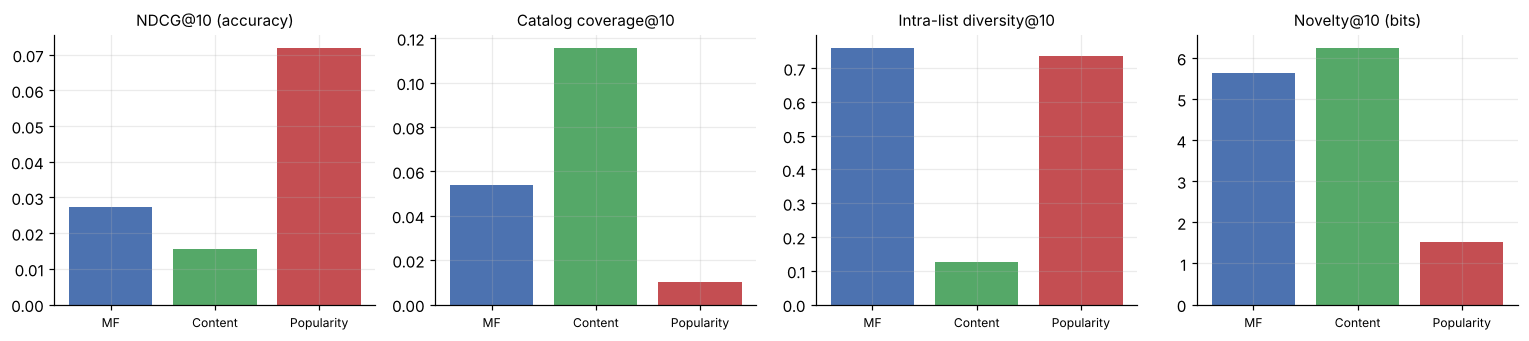

In [22]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
names = ["MF", "Content", "Popularity"]; cols = ["#4c72b0", "#55a868", "#c44e52"]
for a, (m, t) in zip(ax, [("NDCG@10", "NDCG@10 (accuracy)"), ("Coverage@10", "Catalog coverage@10"), ("Diversity@10", "Intra-list diversity@10"), ("Novelty@10", "Novelty@10 (bits)")]):
    a.bar(names, tab5[m].values, color=cols); a.set_title(t, fontsize=10); a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

### 5.1 Why a model that maximises Precision@K / NDCG alone can still ship a worse product

Accuracy metrics are computed against what users *historically rated*, and historical ratings are dominated by whatever was already popular and already shown. A model that simply maximises those metrics is rewarded for
recommending the blockbusters everybody has already rated highly: they are the safest bets, so Precision@K and NDCG look healthy. The popularity baseline above is the extreme case — it can look surprisingly competitive on accuracy while covering
a tiny sliver of the catalog, giving every user nearly the same list, and showing almost nothing the user could not have found on the front page. Such a system is accurate and **useless**: no discovery, no value from the long tail (where
catalog breadth and often margin live), exposure concentrated on a few titles, and creators of everything else never get an audience.

It also feeds the **filter bubble** from Task 11: the more the system shows items similar to what the user already liked, the more their future ratings concentrate on that same slice, the more the next model is trained on that slice, and the
narrower the recommendations become. A slightly *less* accurate model with higher diversity, coverage and novelty can therefore deliver a **better** experience — users keep discovering things, stay engaged longer, and the catalog stays alive —
even though every offline accuracy number is a little lower. That is why accuracy is only one axis: production teams track accuracy together with coverage, diversity, novelty/serendipity, and judge trade-offs in an online experiment (Phase 8), not on Precision@K alone.

---
## Phase 6 — The Cold Start Problem

### 6.1 Three variants

| Variant | Situation | Why collaborative filtering struggles |
|---|---|---|
| **New user** | a user with no or very few interactions | the user has no row to learn a latent vector from, so `p_u` is a guess from 1–2 noisy points |
| **New item** | an item with no or very few interactions | the item has no column to learn `q_i` / `b_i` from; it cannot be scored at all |
| **System (new platform)** | a brand-new product with a near-empty interaction matrix | there is not enough co-occurrence anywhere for the latent structure to be learnable |

### 6.2 Reproduction 1 — new-user cold start

**Protocol (leak-free).** If we kept the user's full history inside the fitted model and merely hid some ratings at prediction time, the item factors would already "know" the user. So instead:

1. Pick a random 25 % of the eligible test users as **cold users**.
2. Fit the MF model **without any of their ratings** (warm users only).
3. For a cold user keep only their **first `n` training interactions** (by timestamp) and *fold them in*: solve for the user's bias and factor vector with the item side frozen (exactly what a production system does for a new user).
4. Evaluate on the cold users' temporal test items, exactly as in Phase 4.

cold users: 148 | warm training ratings: 61,319 | MF knows these cold users: False


,MF NDCG@10,MF P@10,Content NDCG@10,Content P@10,Popularity NDCG@10,Popularity P@10
interactions kept,,,,,,
1,0.0493,0.0324,0.0062,0.0054,0.0684,0.0473
2,0.0291,0.0203,0.0050,0.0054,0.0684,0.0473
3,0.0315,0.0230,0.0033,0.0047,0.0684,0.0473
5,0.0281,0.0203,0.0080,0.0054,0.0684,0.0473
10,0.0240,0.0216,0.0115,0.0068,0.0684,0.0473
20,0.0318,0.0264,0.0101,0.0068,0.0684,0.0473
50,0.0391,0.0345,0.0139,0.0101,0.0684,0.0473
all,0.0427,0.0365,0.0166,0.0101,0.0684,0.0473


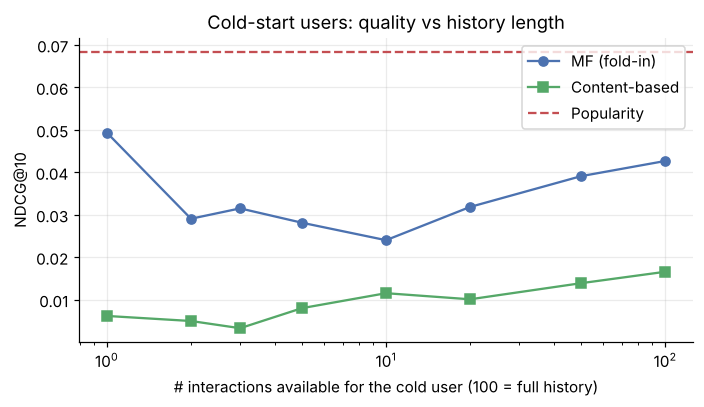

In [23]:
rs = np.random.default_rng(SEED)
cold_users = np.sort(rs.choice(ev.users, size=int(round(0.25 * len(ev.users))), replace=False))
is_cold = np.zeros(n_users, bool); is_cold[cold_users] = True
train_warm = train_t[~is_cold[train_t.u.values]]
mf_warm = BiasALS(**BEST).fit(train_warm, n_users, n_items)           # has never seen a single rating of a cold user
ev_cold = Evaluator(train_t, test_t, users=cold_users)                  # same train mask / test items, but only the cold users are scored
S_pop_warm = popularity_scores(train_warm, n_users, n_items)
print(f"cold users: {len(cold_users)} | warm training ratings: {len(train_warm):,} | MF knows these cold users: {bool(mf_warm.user_known[cold_users].any())}")

def first_n(train, mask_users, n):
    d = train[mask_users[train.u.values]].sort_values(["u", "timestamp", "i"], kind="mergesort")
    return d.groupby("u").head(n) if n is not None else d

def nth_only(train, mask_users, n):
    d = train[mask_users[train.u.values]].sort_values(["u", "timestamp", "i"], kind="mergesort")
    return d.groupby("u").nth(n - 1)

def cold_scores(hist):
    bu_c, P_c = mf_warm.fold_in(hist)                                   # new-user fold-in; item side frozen
    return mf_warm.score_matrix(P_c, bu_c), content_scores(hist, F, n_users, n_items)

def jaccard(a, b):
    return np.array([len(set(x) & set(y)) / len(set(x) | set(y)) for x, y in zip(a, b)])

n_keeps = [1, 2, 3, 5, 10, 20, 50, None]                                # None = the user's full training history
rows, tops_cache, cold_ndcg = [], {}, {}
for nk in n_keeps:
    hist = first_n(train_t, is_cold, nk)
    S_m, S_c = cold_scores(hist)
    tm, tc = ev_cold.topk(S_m), ev_cold.topk(S_c)
    tops_cache[nk] = tm
    mm, mc = ev_cold.metrics(top=tm), ev_cold.metrics(top=tc)
    cold_ndcg[nk] = {"MF": mm["NDCG@10"].values, "Content": mc["NDCG@10"].values}     # per-user arrays (aligned with ev_cold.users), reused in Phase 7
    rows.append({"interactions kept": "all" if nk is None else nk, "MF NDCG@10": mm["NDCG@10"].mean(), "MF P@10": mm["P@10"].mean(),
                 "Content NDCG@10": mc["NDCG@10"].mean(), "Content P@10": mc["P@10"].mean()})
pop_met = ev_cold.metrics(S_pop_warm)
cold_tbl = pd.DataFrame(rows).set_index("interactions kept")
cold_tbl["Popularity NDCG@10"] = pop_met["NDCG@10"].mean(); cold_tbl["Popularity P@10"] = pop_met["P@10"].mean()
display(cold_tbl)
RESULTS["cold_tbl"] = cold_tbl.copy()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
xs = [1, 2, 3, 5, 10, 20, 50, 100]
ax.plot(xs, cold_tbl["MF NDCG@10"].values, marker="o", label="MF (fold-in)", color="#4c72b0")
ax.plot(xs, cold_tbl["Content NDCG@10"].values, marker="s", label="Content-based", color="#55a868")
ax.axhline(pop_met["NDCG@10"].mean(), color="#c44e52", ls="--", label="Popularity")
ax.set(xscale="log", xlabel="# interactions available for the cold user (100 = full history)", ylabel="NDCG@10", title="Cold-start users: quality vs history length"); ax.legend()
plt.tight_layout(); plt.show()

In [24]:
# Instability of MF recommendations when only 1 (or 2) interactions exist
full_top = tops_cache[None]
print(f"mean Jaccard overlap of the top-10 list with the full-history list (cohort of {len(cold_users)} cold users):")
for nk in (1, 2, 5, 20):
    print(f"   {nk:>2} interactions kept -> {jaccard(tops_cache[nk][:, :10], full_top[:, :10]).mean():.3f}")

# same user, different single interaction => completely different list?  (list from interaction #1 only  vs  from interaction #2 only)
h1, h2 = nth_only(train_t, is_cold, 1), nth_only(train_t, is_cold, 2)
t1, t2 = ev_cold.topk(cold_scores(h1)[0]), ev_cold.topk(cold_scores(h2)[0])
print(f"\nmean Jaccard between the list built from the user's 1st interaction alone and from their 2nd interaction alone: {jaccard(t1[:, :10], t2[:, :10]).mean():.3f}")
print("(1.0 would mean the recommendations do not depend on which single rating we happened to see; 0 means they share nothing.)")

# a single cold user, side by side
cu = int(cold_users[0]); pos_cu = int(np.where(ev_cold.users == cu)[0][0])
first2 = first_n(train_t, is_cold, 2); first2 = first2[first2.u == cu]
print(f"\ncold user userId={user_ids[cu]}  | first two interactions:")
for _, r in first2.iterrows(): print(f"    {movies.title.values[int(r.i)]}  ->  {r.rating:g} stars")
side = pd.DataFrame({"rank": range(1, 11),
                     "MF, 1 interaction": movies.title.values[tops_cache[1][pos_cu, :10]],
                     "MF, 2 interactions": movies.title.values[tops_cache[2][pos_cu, :10]],
                     "MF, full history": movies.title.values[full_top[pos_cu, :10]]}).set_index("rank")
with pd.option_context("display.max_colwidth", 38):
    display(side)

mean Jaccard overlap of the top-10 list with the full-history list (cohort of 148 cold users):
    1 interactions kept -> 0.363
    2 interactions kept -> 0.262
    5 interactions kept -> 0.251
   20 interactions kept -> 0.500



mean Jaccard between the list built from the user's 1st interaction alone and from their 2nd interaction alone: 0.401
(1.0 would mean the recommendations do not depend on which single rating we happened to see; 0 means they share nothing.)

cold user userId=6  | first two interactions:
    Dances with Wolves (1990)  ->  5 stars
    Batman (1989)  ->  3 stars


,"MF, 1 interaction","MF, 2 interactions","MF, full history"
rank,,,
1,Land Before Time III: The Time of ...,Land Before Time III: The Time of ...,Dr. Strangelove or: How I Learned ...
2,Casablanca (1942),"Invisible, The (2007)","Princess Bride, The (1987)"
3,Dr. Strangelove or: How I Learned ...,Fullmetal Alchemist 2018 (2017),Star Wars: Episode V - The Empire ...
4,Lawrence of Arabia (1962),Secret Society (2002),American History X (1998)
5,"Princess Bride, The (1987)",Urban Legends: Final Cut (2000),"Departed, The (2006)"
6,Wallace & Gromit: The Best of Aard...,Prom Night (2008),"Dark Knight, The (2008)"
7,"Invisible, The (2007)",Daddy Day Camp (2007),Star Wars: Episode IV - A New Hope...
8,Goodfellas (1990),Pokemon 4 Ever (a.k.a. Pokémon 4: ...,Goodfellas (1990)
9,"Philadelphia Story, The (1940)",Jeepers Creepers 2 (2003),Star Wars: Episode VI - Return of ...


**What the reproduction shows.** With one or two interactions, MF has almost nothing to estimate a latent vector from, so the fold-in is dominated by the regulariser and by the item biases. Read the numbers above as follows:
the **Jaccard overlaps** say how much the list changes with *which* single rating happened to be observed and how far it is from what the same user gets once their history is known (1.0 = identical, 0 = nothing in common), and the **table / plot** show how quality changes as history grows.

In [25]:
mf_1, mf_full = cold_tbl.loc[1, "MF NDCG@10"], cold_tbl.loc["all", "MF NDCG@10"]
ct_1, ct_full = cold_tbl.loc[1, "Content NDCG@10"], cold_tbl.loc["all", "Content NDCG@10"]
print(f"MF NDCG@10 with 1 interaction = {mf_1:.4f} vs {mf_full:.4f} with the full history ({mf_1 / mf_full:.0%} of full-history quality).")
print(f"Content-based NDCG@10 with 1 interaction = {ct_1:.4f} vs {ct_full:.4f} with the full history ({ct_1 / ct_full:.0%}).")
print("Popularity needs no user history at all, which is why it is the natural fallback for a user with nothing (Exercise 3).")

MF NDCG@10 with 1 interaction = 0.0493 vs 0.0427 with the full history (116% of full-history quality).
Content-based NDCG@10 with 1 interaction = 0.0062 vs 0.0166 with the full history (37%).
Popularity needs no user history at all, which is why it is the natural fallback for a user with nothing (Exercise 3).


### 6.3 Reproduction 2 — new-item cold start

We add a brand-new movie to the catalog with **zero ratings** (genres known, as they would be at ingestion time) and ask both models to rank it.

In [26]:
new_decade = max(featurizer.decades_)
new_row = pd.DataFrame({"movieId": [int(item_ids.max()) + 1], "title": [f"Brand New Movie ({new_decade + 5})"], "genres": ["Action|Sci-Fi"]})
movies_plus = pd.concat([movies[["movieId", "title", "genres"]], new_row], ignore_index=True)
new_idx = n_items                                                      # the position the new movie would occupy
print("new movie added to the catalog:", new_row.iloc[0].to_dict(), "| ratings for it: 0")

# ---- matrix factorization: there is literally no embedding ----
print(f"\nMF item-factor matrix has {mf.Q.shape[0]:,} rows (indices 0..{mf.Q.shape[0]-1}); the new movie would need index {new_idx}.")
try:
    _ = mf.Q[new_idx]
except IndexError as e:
    print("MF lookup of the new item ->", type(e).__name__, ":", e)
print("The model was trained only on items that have ratings -> no q_i and no b_i exists for it.")
# the closest thing to a fix: fold the item in with ZERO ratings -> ridge regression with no data returns the zero vector
empty = sp.csr_matrix((1, n_users))
b_new, q_new = _ridge_rows(mf.P, mf.bu, mf.mu, empty.indptr, empty.indices, empty.data, mf.reg, mf.k, mf.item_bias_damping)
print(f"fold-in with zero ratings -> bias={b_new[0]:.3f}, |q|={np.linalg.norm(q_new):.3f}  (all zeros: nothing was learned)")
score_new = mf.mu + mf.bu                                                # predicted score of the new item for every user = mu + b_u (+0 +0)
kth = np.sort(np.where(ev.seen, -np.inf, S_mf), axis=1)[:, -10]          # each user's 10th-best score
print(f"the new item gets the same score mu + b_u for everyone; it would enter a user's top-10 for {(score_new[ev.users] > kth[ev.users]).sum()} of {len(ev.users)} users.")
n_unrated = int((~mf.item_known).sum())
print(f"(Same story for the {n_unrated} catalog movies that already have no training ratings: MF scores them -inf; appearances in any top-10 = {np.isin(np.where(~mf.item_known)[0], top_mf[:, :10]).sum()}.)")

# ---- content-based: the item exists the moment its metadata exists ----
f_new = featurizer.transform(new_row)                                    # (1, d) feature vector from metadata alone
F_plus = np.vstack([F, f_new])
W = interest_weights(train_t, n_users, n_items)
prof = W @ F; prof /= np.maximum(np.linalg.norm(prof, axis=1, keepdims=True), 1e-12)
S_plus = np.hstack([prof @ F.T, prof @ f_new.T])                         # scores for the original catalog + the new movie
seen_plus = np.hstack([ev.seen, np.zeros((n_users, 1), bool)])
S_plus = np.where(seen_plus, -np.inf, S_plus)
rank_new = (S_plus > S_plus[:, [new_idx]]).sum(1) + 1                    # 1 = best
elig_rank = rank_new[ev.users]
print(f"\ncontent-based model: the new movie gets a real score for every user. Its rank among ~{n_items:,} candidates:")
print(f"   median rank = {int(np.median(elig_rank)):,} | best rank = {int(elig_rank.min())} | in a user's top-50 for {(elig_rank <= 50).sum()} users | in top-10 for {(elig_rank <= 10).sum()} users")
sample_u = int(ev.users[np.argmin(elig_rank)])
print(f"   e.g. userId={user_ids[sample_u]} (their best-matching profile) would see it at rank {int(rank_new[sample_u])}, i.e. in the top {100 * rank_new[sample_u] / n_items:.1f}% of the catalog")
print("   (a movie described only by two genres competes with thousands of near-identical vectors, so a content-only score is coarse - but it is a real, user-specific score, which MF cannot produce at all.)")

new movie added to the catalog: {'movieId': 193610, 'title': 'Brand New Movie (2015.0)', 'genres': 'Action|Sci-Fi'} | ratings for it: 0

MF item-factor matrix has 9,742 rows (indices 0..9741); the new movie would need index 9742.
MF lookup of the new item -> IndexError : index 9742 is out of bounds for axis 0 with size 9742
The model was trained only on items that have ratings -> no q_i and no b_i exists for it.
fold-in with zero ratings -> bias=0.000, |q|=0.000  (all zeros: nothing was learned)
the new item gets the same score mu + b_u for everyone; it would enter a user's top-10 for 0 of 592 users.
(Same story for the 1503 catalog movies that already have no training ratings: MF scores them -inf; appearances in any top-10 = 0.)

content-based model: the new movie gets a real score for every user. Its rank among ~9,742 candidates:
   median rank = 5,897 | best rank = 68 | in a user's top-50 for 0 users | in top-10 for 0 users
   e.g. userId=149 (their best-matching profile) would see 

### 6.4 Why content-based filtering solves new-item cold start but not new-user cold start

* **New item ✔.** A content-based recommender scores an item from its **own attributes** (genres, year, cast, text…). Those exist at ingestion time, before a single user has interacted with the item. The score for the new movie is just "how similar are its features to this user's profile?" — no interaction history of the *item* is required, and the cell above shows it receiving a defined, user-specific score and rank for every user (how *high* it ranks depends on how distinctive its metadata is — richer metadata such as tags, cast or a text description would separate it from the thousands of look-alike vectors).
* **New user ✘ (only partially).** The user profile is *built from the items the user liked*. With zero interactions the profile is the zero vector, so every item scores the same; with one or two interactions the profile is a thin, noisy slice of taste. Content-based filtering can build a profile from a single liked item (compare the Content and MF columns of the cohort table at 1–3 interactions to see how good that thin profile actually is) but it still needs *some* signal — which is why the user-side mitigations below are about getting signal quickly.
* **System cold start** hits CF hardest (no co-occurrence anywhere) and content-based least (item metadata exists on day one) — demonstrated next.

### 6.5 System cold start — shrinking the whole interaction matrix

To simulate a brand-new platform we train on a random fraction of the training interactions and evaluate on the same temporal test set.

,interactions,MF NDCG@10,Content NDCG@10,Popularity NDCG@10
fraction of training data,,,,
0.020000,"1,613",0.021361,0.018432,0.046527
0.050000,"4,034",0.015175,0.016645,0.054713
0.100000,"8,067",0.018463,0.012095,0.062548
0.250000,"20,168",0.023433,0.012481,0.066369
0.500000,"40,336",0.024588,0.015842,0.068608
1.000000,"80,672",0.027374,0.015551,0.071936


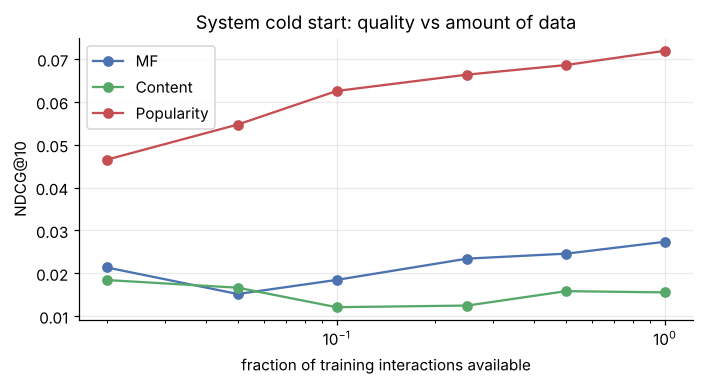

In [27]:
rows = []
for f in (0.02, 0.05, 0.10, 0.25, 0.50, 1.00):
    sub = train_t.sample(frac=f, random_state=SEED) if f < 1 else train_t
    m_f = BiasALS(**BEST).fit(sub, n_users, n_items)
    r = {"fraction of training data": f, "interactions": len(sub)}
    for name, S in (("MF", m_f.score_matrix()), ("Content", content_scores(sub, F, n_users, n_items)), ("Popularity", popularity_scores(sub, n_users, n_items))):
        r[f"{name} NDCG@10"] = ev.metrics(S)["NDCG@10"].mean()
    rows.append(r)
sys_tbl = pd.DataFrame(rows).set_index("fraction of training data")
display(sys_tbl.style.format({"interactions": "{:,.0f}"}))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for c, col in zip(["MF NDCG@10", "Content NDCG@10", "Popularity NDCG@10"], ["#4c72b0", "#55a868", "#c44e52"]):
    ax.plot(sys_tbl.index, sys_tbl[c], marker="o", label=c.split()[0], color=col)
ax.set(xscale="log", xlabel="fraction of training interactions available", ylabel="NDCG@10", title="System cold start: quality vs amount of data"); ax.legend()
plt.tight_layout(); plt.show()

### 6.6 Cold-start mitigations

| Variant | Standard mitigations | Notes |
|---|---|---|
| **New user** | **Onboarding questions** ("pick 5 genres / rate 10 titles you know") to obtain real signal immediately · **demographic / contextual defaults** (country, language, device, time of day) · **trending / popular items** until enough interactions accumulate · switch to a **content-based or fold-in model** as soon as 1–2 interactions arrive (Phase 7 switching hybrid) | The goal is to collect signal fast; exploration (showing varied items) speeds that up |
| **New item** | **Content-based fallback**: score the item from its metadata and show it to users whose profile is similar · **item-to-item similarity** to already-popular items · **explicit exploration slots** (bandit-style boost) so it gets its first impressions · feature-based/hybrid models that map metadata to a latent vector | Metadata quality is the bottleneck: garbage genres/tags → garbage new-item recommendations |
| **System (new platform)** | **Bootstrap with content-based filtering** and non-personalised popularity/editorial lists · import **external data** (public ratings, catalog metadata, partner data) · run popularity + content until the interaction matrix is dense enough, then phase in CF (a **weighted/switching hybrid** whose weight on CF grows with data) | Compare the columns of the 6.5 table to see where (if anywhere) MF overtakes the simpler models on your data |

---
## Phase 7 — Hybrid Recommendation Strategies

### 7.1 The five standard strategies

| Strategy | How it works | Implemented here? |
|---|---|---|
| **Weighted** | blend the (normalised) scores of several recommenders with tunable weights | ✔ 7.2 |
| **Switching** | pick *one* recommender per user/context (e.g. content-based for cold-start users, CF otherwise) | ✔ 7.3 |
| **Mixed** | show results from several recommenders side-by-side in the same page/list | table 7.4 |
| **Feature combination** | feed one recommender's signal as an input feature to another | table 7.4 |
| **Cascade** | one recommender produces a coarse shortlist, a second refines / re-ranks it | ✔ 7.5 (small demo) |

### 7.2 Weighted hybrid:  `hybrid(u,i) = α·CF(u,i) + (1−α)·content(u,i)`

MF scores are in "stars" and content scores are cosines in [0, 1], so they cannot be added raw. Each recommender's scores are first **standardised per user** (z-score over that user's candidate items);
items the MF model cannot score (no training ratings) get that user's lowest CF z-score, so for them the hybrid falls back to the content signal.

`α` is chosen on **validation** data — a temporal split carved out of the training data (`inner_train` → `valid`), so the test set stays untouched — and only then reported on the test set.

,validation NDCG@10,test NDCG@10 (reference only)
alpha,,
0.0000,0.0153,0.0156
0.1000,0.0171,0.0173
0.2000,0.0231,0.0218
0.3000,0.0272,0.0258
0.4000,0.0309,0.0297
0.5000,0.0333,0.0314
0.6000,0.0352,0.0317
0.7000,0.0358,0.0303
0.8000,0.0342,0.0315


best alpha on VALIDATION data: 0.7  (validation NDCG@10 = 0.0358)


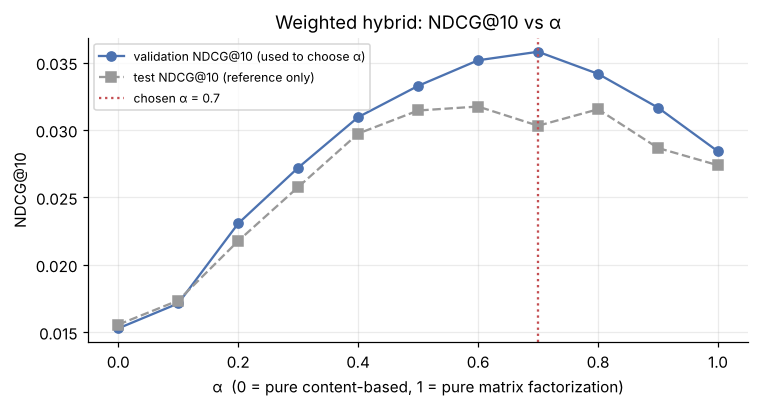

In [28]:
def zscore_rows(S, seen):
    """Per-user standardisation over unseen, finite scores; seen/unscorable entries get the user's minimum."""
    ok = np.isfinite(S) & ~seen
    cnt = ok.sum(1, keepdims=True).clip(1)
    Sz = np.where(ok, S, 0.0)
    mu_ = Sz.sum(1, keepdims=True) / cnt
    sd = np.sqrt((np.where(ok, S - mu_, 0.0) ** 2).sum(1, keepdims=True) / cnt).clip(1e-9)
    Z = np.where(ok, (S - mu_) / sd, np.inf)
    zmin = np.min(np.where(ok, Z, np.inf), axis=1, keepdims=True)
    return np.where(ok, Z, zmin)

def weighted_hybrid(S_cf, S_cb, alpha, seen):
    return alpha * zscore_rows(S_cf, seen) + (1 - alpha) * zscore_rows(S_cb, seen)

alphas = np.round(np.linspace(0, 1, 11), 2)

# ---- validation: models trained on inner_train, evaluated on `valid` ----
ev_val = Evaluator(inner_train, valid)
S_cf_val = mf_inner.score_matrix()
S_cb_val = content_scores(inner_train, F, n_users, n_items)
Z_cf_val, Z_cb_val = zscore_rows(S_cf_val, ev_val.seen), zscore_rows(S_cb_val, ev_val.seen)
val_curve = [ev_val.metrics(a * Z_cf_val + (1 - a) * Z_cb_val, ks=(10,))["NDCG@10"].mean() for a in alphas]

# ---- test: models trained on the full temporal training set (for reference only, NOT used to choose alpha) ----
Z_cf_te, Z_cb_te = zscore_rows(S_mf, ev.seen), zscore_rows(S_cb, ev.seen)
test_curve = [ev.metrics(a * Z_cf_te + (1 - a) * Z_cb_te, ks=(10,))["NDCG@10"].mean() for a in alphas]

best_i = int(np.argmax(val_curve)); ALPHA = float(alphas[best_i])
sweep = pd.DataFrame({"alpha": alphas, "validation NDCG@10": val_curve, "test NDCG@10 (reference only)": test_curve}).set_index("alpha")
display(sweep)
print(f"best alpha on VALIDATION data: {ALPHA:.1f}  (validation NDCG@10 = {val_curve[best_i]:.4f})")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(alphas, val_curve, marker="o", color="#4c72b0", label="validation NDCG@10 (used to choose α)")
ax.plot(alphas, test_curve, marker="s", ls="--", color="#999999", label="test NDCG@10 (reference only)")
ax.axvline(ALPHA, color="#c44e52", ls=":", label=f"chosen α = {ALPHA:.1f}")
ax.set(xlabel="α  (0 = pure content-based, 1 = pure matrix factorization)", ylabel="NDCG@10", title="Weighted hybrid: NDCG@10 vs α"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [29]:
S_hyb = weighted_hybrid(S_mf, S_cb, ALPHA, ev.seen)               # the Phase 7 "treatment" model used in Phase 8
top_hyb = ev.topk(S_hyb); met_hyb = ev.metrics(top=top_hyb)
final = pd.DataFrame({"Content-based (α=0)": met_cb.mean(), f"Weighted hybrid (α={ALPHA:.1f})": met_hyb.mean(), "Matrix factorization (α=1)": met_mf.mean()}).T
display(final[["P@10", "R@10", "AP@10", "NDCG@10", "RR@10"]].rename(columns={"AP@10": "MAP@10", "RR@10": "MRR@10"}))
RESULTS["alpha"], RESULTS["ndcg10_hybrid"] = ALPHA, float(met_hyb["NDCG@10"].mean())
# the pure-endpoint hybrids must reproduce the single models (sanity check on the blending code)
assert np.allclose(ev.metrics(weighted_hybrid(S_mf, S_cb, 1.0, ev.seen), ks=(10,))["NDCG@10"], met_mf["NDCG@10"])
assert np.allclose(ev.metrics(weighted_hybrid(S_mf, S_cb, 0.0, ev.seen), ks=(10,))["NDCG@10"], met_cb["NDCG@10"])
print("alpha=1 reproduces MF and alpha=0 reproduces content-based exactly  OK")

,P@10,R@10,MAP@10,NDCG@10,MRR@10
Content-based (α=0),0.0115,0.0141,0.0063,0.0156,0.0346
Weighted hybrid (α=0.7),0.0270,0.0216,0.0144,0.0303,0.0760
Matrix factorization (α=1),0.0258,0.0201,0.0129,0.0274,0.0650


alpha=1 reproduces MF and alpha=0 reproduces content-based exactly  OK


### 7.3 Switching hybrid — cold-start comparison

Policy: **if the user has fewer than `N` interactions → serve content-based recommendations, otherwise → matrix factorization.**

To choose `N` without peeking at the numbers we report, the 25 % cold-user cohort from Phase 6 is split into two halves: **half A tunes `N`**, **half B evaluates it**.
Each cold user is replayed through their "life-cycle" (1, 2, 3, 5, 10, 20, 50 interactions, then full history), and `N` is the candidate that gives the best NDCG@10 averaged over that whole life-cycle on half A.

In [30]:
perm = np.random.default_rng(SEED + 1).permutation(len(ev_cold.users))
half_A, half_B = perm[: len(perm) // 2], perm[len(perm) // 2:]
lifecycle = [1, 2, 3, 5, 10, 20, 50, None]
n_label = lambda nk: 100 if nk is None else nk                         # "all" history counts as >= 100 interactions for the policy

def policy_ndcg(idx, N):
    """mean NDCG@10 over users `idx` and over the life-cycle when the policy is: n < N -> content, else MF."""
    vals = []
    for nk in lifecycle:
        src = "Content" if n_label(nk) < N else "MF"
        vals.append(cold_ndcg[nk][src][idx].mean())
    return float(np.mean(vals))

cand_N = [1, 2, 3, 5, 10, 20, 50, 101]                                  # N=1: always MF ; N=101: always content
tune = pd.DataFrame({"N": cand_N, "half A: life-cycle NDCG@10": [policy_ndcg(half_A, N) for N in cand_N],
                     "half B: life-cycle NDCG@10": [policy_ndcg(half_B, N) for N in cand_N]}).set_index("N")
display(tune)
N_STAR = int(tune["half A: life-cycle NDCG@10"].idxmax())
print(f"N chosen on half A = {N_STAR}  ({'always MF' if N_STAR == 1 else 'always content' if N_STAR == 101 else f'content-based for users with < {N_STAR} interactions, MF otherwise'})")

rows = []
for nk in lifecycle:
    src = "Content" if n_label(nk) < N_STAR else "MF"
    rows.append({"interactions": "all" if nk is None else nk, "pure MF": cold_ndcg[nk]["MF"][half_B].mean(), "pure content": cold_ndcg[nk]["Content"][half_B].mean(),
                 f"switching (N={N_STAR})": cold_ndcg[nk][src][half_B].mean(), "switching serves": src})
sw = pd.DataFrame(rows).set_index("interactions")
display(sw.style.format({c: "{:.4f}" for c in sw.columns if c != "switching serves"}))
cold_range = [1, 2, 3, 5]
mf_cold = np.mean([cold_ndcg[k]["MF"][half_B].mean() for k in cold_range]); sw_cold = np.mean([cold_ndcg[k]["Content" if k < N_STAR else "MF"][half_B].mean() for k in cold_range])
print(f"\nhalf B, masked-user scenario (1-5 interactions): pure MF NDCG@10 = {mf_cold:.4f} | switching = {sw_cold:.4f}  ({(sw_cold - mf_cold) / max(mf_cold, 1e-12):+.1%} relative)")
print(f"half B, whole life-cycle: pure MF = {np.mean([cold_ndcg[k]['MF'][half_B].mean() for k in lifecycle]):.4f} | switching = {policy_ndcg(half_B, N_STAR):.4f}")
RESULTS["N_switch"], RESULTS["switch_cold_vs_mf"] = N_STAR, (sw_cold, mf_cold)

# paired bootstrap over half-B users for (switching - MF) in the masked scenario
d_user = np.mean([cold_ndcg[k]["Content" if k < N_STAR else "MF"][half_B] - cold_ndcg[k]["MF"][half_B] for k in cold_range], axis=0)
bs = np.random.default_rng(SEED).choice(d_user, size=(4000, len(d_user)), replace=True).mean(1)
lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"paired bootstrap, mean per-user NDCG@10 difference (switching - MF) = {d_user.mean():+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}] over {len(d_user)} users")
verdict = "does NOT reliably differ from" if lo <= 0 <= hi else ("BEATS" if d_user.mean() > 0 else "is WORSE than")
print(f"=> on this data the switching hybrid {verdict} pure MF in the masked-user scenario.")

,half A: life-cycle NDCG@10,half B: life-cycle NDCG@10
N,,
1,0.0384,0.0305
2,0.0322,0.0259
3,0.0295,0.0226
5,0.0254,0.0196
10,0.0222,0.0179
20,0.0192,0.0177
50,0.0148,0.0166
101,0.0069,0.0118


N chosen on half A = 1  (always MF)


,pure MF,pure content,switching (N=1),switching serves
interactions,,,,
1,0.0473,0.0106,0.0473,MF
2,0.0323,0.0061,0.0323,MF
3,0.0289,0.0053,0.0289,MF
5,0.0228,0.0084,0.0228,MF
10,0.0153,0.0143,0.0153,MF
20,0.0218,0.0132,0.0218,MF
50,0.0366,0.0149,0.0366,MF
all,0.0386,0.0214,0.0386,MF



half B, masked-user scenario (1-5 interactions): pure MF NDCG@10 = 0.0328 | switching = 0.0328  (+0.0% relative)
half B, whole life-cycle: pure MF = 0.0305 | switching = 0.0305
paired bootstrap, mean per-user NDCG@10 difference (switching - MF) = +0.0000, 95% CI [+0.0000, +0.0000] over 74 users
=> on this data the switching hybrid does NOT reliably differ from pure MF in the masked-user scenario.


**Reading it.** The switching hybrid can only help where the two models *cross*: below the crossover the content model has a usable signal and MF does not, above it MF takes over.
If the tuned `N` equals 1, MF was already at least as good as content from the very first interaction on this data and switching adds nothing; if it equals the largest candidate, content never loses.
Anything in between is a genuine crossover. Half B is untouched by the tuning, so the comparison above is an honest (if small-sample) estimate; with ~75 users per half, differences of a few percent are within noise — a production team would confirm with an A/B test (Phase 8).

### 7.4 Strategy reference table (with this project's own examples)

| Strategy | How it works | Example use case (this project / MovieLens) |
|---|---|---|
| **Weighted** | Blend scores from multiple recommenders | `0.x · MF score + (1−0.x) · genre-similarity score` for every candidate movie, exactly the α-sweep in 7.2 |
| **Switching** | Pick one recommender based on context / user state | A user with fewer than `N` ratings gets genre-based picks, a user with `N`+ ratings gets MF picks (7.3); a brand-new user with nothing gets "Trending now" |
| **Mixed** | Show results from multiple recommenders together | Home page rows: **"Because you watched *Toy Story*"** (content/item-item) + **"Top picks for you"** (MF) + **"Trending this week"** (popularity) |
| **Feature combination** | Feed one recommender's signal as a feature into another | Use the MF **item embeddings `q_i`** (collaborative signal) as extra input features next to genres/decade in the content model — so two movies with the same genres but different audiences are no longer identical vectors |
| **Cascade** | One recommender narrows candidates; another refines / ranks them | Content/popularity retrieval narrows ~10,000 movies to ~200 candidates in milliseconds; the heavier MF (or later a neural ranker, Task 15) re-ranks only those 200 |

### 7.5 Cascade hybrid — concrete example and a small demo

A **cascade** makes sense when the full catalog is too big to score with the expensive model for every request. Production example: a streaming service with 100,000 titles and tens of millions of users.
Stage 1 (*candidate generation*: approximate nearest-neighbour search over embeddings, or a content / popularity retriever) cuts the catalog to a few hundred candidates in a few milliseconds.
Stage 2 (*ranking*: a slower, more accurate model with many features — e.g. a deep ranker, Task 15) scores only those few hundred and returns the final top-10. Cost drops by orders of magnitude, and stage 2 can use features that would be far too expensive to compute for every item.
The price is a **recall ceiling**: an item stage 1 does not retrieve can never be recommended, however good stage 2 is — so stage 1 is judged by recall of the shortlist, stage 2 by ranking quality.

In [31]:
def cascade_scores(S_stage1, S_stage2, seen, n_cand=200):
    """Stage 1 shortlists n_cand unseen items; stage 2 re-ranks ONLY those (everything else is -inf)."""
    s1 = np.where(seen, -np.inf, S_stage1)
    cand = np.argpartition(-s1, n_cand - 1, axis=1)[:, :n_cand]
    out = np.full_like(S_stage2, -np.inf, dtype=np.float64)
    np.put_along_axis(out, cand, np.take_along_axis(S_stage2, cand, 1), axis=1)
    return out, cand

rows = []
for n_cand in (50, 200, 500):
    S_cas, cand = cascade_scores(S_cb, S_mf, ev.seen, n_cand)           # stage 1 = content-based retrieval, stage 2 = MF re-rank
    cand_el = cand[ev.users]
    short_recall = np.mean([ev.rel[u, c].sum() / ev.n_rel[u] for u, c in zip(ev.users, cand_el)])
    m_ = ev.metrics(S_cas)
    rows.append({"stage-1 shortlist size": n_cand, "share of catalog scored by stage 2": n_cand / n_items,
                 "stage-1 recall of relevant items": short_recall, "cascade NDCG@10": m_["NDCG@10"].mean(), "cascade P@10": m_["P@10"].mean()})
casc = pd.DataFrame(rows).set_index("stage-1 shortlist size")
casc.loc["no cascade (MF on all items)"] = [1.0, 1.0, met_mf["NDCG@10"].mean(), met_mf["P@10"].mean()]
display(casc.style.format({"share of catalog scored by stage 2": "{:.1%}", "stage-1 recall of relevant items": "{:.1%}", "cascade NDCG@10": "{:.4f}", "cascade P@10": "{:.4f}"}))
print("Items outside the shortlist can never be recommended (a recall ceiling); the shortlist also acts as a filter on stage 2's candidates, so end quality can move either way.")
print("Shortlist size trades compute against that ceiling: stage 2 scores only the fraction shown in the second column.")

,share of catalog scored by stage 2,stage-1 recall of relevant items,cascade NDCG@10,cascade P@10
stage-1 shortlist size,,,,
50,0.5%,3.1%,0.0202,0.0133
200,2.1%,8.2%,0.0247,0.0191
500,5.1%,15.3%,0.0272,0.0221
no cascade (MF on all items),100.0%,100.0%,0.0274,0.0258


Items outside the shortlist can never be recommended (a recall ceiling); the shortlist also acts as a filter on stage 2's candidates, so end quality can move either way.
Shortlist size trades compute against that ceiling: stage 2 scores only the fraction shown in the second column.


---
## Phase 8 — Online Evaluation: A/B Testing a Recommender

### 8.1 Why offline metrics are necessary but not sufficient

Everything in Phases 2–5 measures how well a model **predicts historical behaviour**: ratings users already gave, to items the *old* system (or the user's own search) had already put in front of them. That has hard limits:

* **Selection / exposure bias.** We only see feedback on items users were shown or found themselves. A new model that surfaces genuinely different items is judged against labels that cannot reward it (an unrated item counts as "irrelevant"), so offline metrics systematically favour models that imitate the old system — see how strongly the popularity baseline can score above.
* **No reaction to the new behaviour.** Offline data cannot tell us how users respond to recommendations they have never seen: whether they click, watch to the end, come back tomorrow, or churn.
* **The wrong target.** NDCG on held-out ratings is a proxy. The business cares about engagement, retention and revenue, which also depend on position, presentation, latency and novelty.
* **Feedback loops.** Recommendations change future behaviour and therefore future training data; a static test set cannot show that.

Offline evaluation is the cheap **screen** that discards obviously bad candidates; the A/B test is the **verdict**.

### 8.2 Experiment design — treatment: Phase 7 weighted hybrid · control: Task 12 pure matrix factorization

| Item | Design |
|---|---|
| **Randomization unit** | the **user** (not the request, session or device): hash `user_id + experiment_salt` into buckets, 50 % control / 50 % treatment. A user always sees the same variant, which prevents users seeing both algorithms (contamination) and keeps their sessions independent of the other arm. Users are the unit of analysis too (so the independence assumption holds). |
| **Control (A)** | Task 12 matrix-factorization recommender |
| **Treatment (B)** | weighted hybrid `α·MF + (1−α)·content` with the α selected in 7.2 |
| **Primary metric** | **click-through rate on recommended items**, defined per user as *users with ≥ 1 click on a recommended title ÷ exposed users* (a proportion), with *plays started per exposed user* as the continuous secondary |
| **Guardrail metrics** (must **not** get worse) | (1) **session length / watch time per user** (a clickbait-y model can raise CTR while lowering satisfaction); (2) **unsubscribe / churn (7-day cancellation) rate**; (3) **recommendation latency p95** (the hybrid scores two models); (4) **catalog coverage & diversity of impressions** (guards against collapsing into a filter bubble); (5) hide / "not interested" rate |
| **Exposure & duration** | only users who actually saw the recommendation surface enter the analysis; run for **≥ 2 full weeks** (see novelty effect), fixed in advance — no peeking-driven stopping |
| **Quality checks before reading results** | **sample-ratio-mismatch** test (observed 50/50 split vs expected, χ²), A/A test of the pipeline, logging checks |

### 8.3 Hypotheses and test choice (Task 5 framework)

* **H₀:** the CTR of treatment equals the CTR of control, `p_B = p_A`.
* **H₁:** `p_B ≠ p_A` (two-sided; a one-sided `p_B > p_A` is only legitimate if pre-registered). Significance level α_test = 0.05, power 80 %.
* **Test:** the primary metric is a *proportion* measured on a **very large** sample (tens of thousands of users per arm, far above the n ≥ 30 rule), so the sampling distribution of the difference is normal and the population variance is estimated from the data →
  a **two-sample Z-test for proportions** (pooled variance under H₀). For the continuous guardrails (session length per user) the Task 5 decision tree gives a **Welch t-test** (unknown, possibly unequal variances), which is numerically ≈ a Z-test at this sample size.
  Because several guardrails are tested at once, control the false-alarm rate (Holm/Bonferroni) for the *ship / no-ship* decision, and report confidence intervals, not just p-values.

### 8.4 The novelty effect

A new algorithm often shows a short-term engagement bump **simply because it shows users something different** — curiosity, not preference. The bump fades as the novelty wears off, so a 3-day test can declare a winner that loses in week 3 (and the opposite can also happen: the old model's "change aversion" penalty for a new one).
Mitigations:
1. **Run long enough** — at least two full weekly cycles, and read the effect **by day since first exposure**: a treatment effect that decays over time is a novelty signature.
2. **Segment** new-vs-returning users and heavy-vs-light users — the novelty effect concentrates in habitual users.
3. **Long-term holdout** — keep a small (e.g. 1–5 %) group on the control (or never-personalised) experience for weeks/months after launch, and keep comparing; the gap that survives is the real, durable effect.
4. Prefer **retention / return-visit** metrics for the final decision over first-session clicks.

### 8.5 Never ship on offline metrics alone

Offline metrics (RMSE, P@K, NDCG, coverage…) are cheap, fast and repeatable, which makes them perfect for **screening** hundreds of candidate models and ruling out the clearly bad ones.
But they are computed on data generated by the *old* system, cannot see user reaction to new behaviour, and optimise a proxy. The A/B test measures the actual outcome — causally, because randomisation balances everything else —
so the decision rule is: **offline metrics decide what is worth testing; the A/B test decides what ships**, and the long-term holdout decides whether it keeps its value.

In [32]:
# Illustrative power analysis for the primary metric. The baseline CTR and the effect size below are ASSUMPTIONS for planning, not results from this notebook.
def n_per_arm(p_base, rel_lift, alpha=0.05, power=0.80):
    p1, p2 = p_base, p_base * (1 + rel_lift)
    zb, za = stats.norm.ppf(power), stats.norm.ppf(1 - alpha / 2)
    pbar = (p1 + p2) / 2
    return int(np.ceil(((za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2) / (p2 - p1) ** 2))

P_BASE = 0.08                                                         # ASSUMED baseline: 8 % of exposed users click a recommended title
plan = pd.DataFrame({"relative lift to detect": [0.01, 0.02, 0.05, 0.10]})
plan["absolute lift"] = P_BASE * plan["relative lift to detect"]
plan["users needed per arm"] = [n_per_arm(P_BASE, r) for r in plan["relative lift to detect"]]
display(plan.style.format({"relative lift to detect": "{:.0%}", "absolute lift": "{:.4f}", "users needed per arm": "{:,.0f}"}))

def two_prop_ztest(x1, n1, x2, n2):
    p1, p2, p = x1 / n1, x2 / n2, (x1 + x2) / (n1 + n2)
    z = (p2 - p1) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return z, 2 * (1 - stats.norm.cdf(abs(z)))

# Mechanics of the test on SIMULATED data (assumed rates), plus an A/A run to show the false-positive rate is ~ the nominal 5 %
rs = np.random.default_rng(SEED)
n = n_per_arm(P_BASE, 0.05)
xA, xB = rs.binomial(n, P_BASE), rs.binomial(n, P_BASE * 1.05)
z, pval = two_prop_ztest(xA, n, xB, n)
print(f"simulated A/B (n={n:,}/arm, true lift +5%): CTR_A={xA/n:.4f}, CTR_B={xB/n:.4f}, Z={z:.2f}, p={pval:.4f} -> {'reject H0' if pval < 0.05 else 'fail to reject H0'}")
aa = [two_prop_ztest(rs.binomial(20000, P_BASE), 20000, rs.binomial(20000, P_BASE), 20000)[1] < 0.05 for _ in range(2000)]
print(f"A/A simulation (no true difference, 2000 experiments): false-positive rate = {np.mean(aa):.3f}  (expected ~0.05)")
srm_p = stats.chisquare([50210, 49790], f_exp=[50000, 50000]).pvalue
print(f"sample-ratio-mismatch check on a hypothetical 50,210 / 49,790 split: chi-square p = {srm_p:.3f}  (p < 0.001 would signal a broken randomisation)")

,relative lift to detect,absolute lift,users needed per arm
0,1%,0.0008,"1,813,479"
1,2%,0.0016,"455,427"
2,5%,0.0040,"73,853"
3,10%,0.0080,"18,872"


simulated A/B (n=73,853/arm, true lift +5%): CTR_A=0.0782, CTR_B=0.0834, Z=3.67, p=0.0002 -> reject H0
A/A simulation (no true difference, 2000 experiments): false-positive rate = 0.058  (expected ~0.05)
sample-ratio-mismatch check on a hypothetical 50,210 / 49,790 split: chi-square p = 0.184  (p < 0.001 would signal a broken randomisation)


---
## Exercises

### Exercise 1 — Popularity baseline vs the Task 12 model (Precision@K and NDCG@K)

Does the "obvious" baseline look competitive on accuracy metrics alone? Same users, same test items, same K as Phases 3–4. A paired bootstrap over users gives a 95 % interval for the NDCG@10 gap.

In [33]:
models_ex = {"Popularity baseline": met_pop, "Matrix factorization (Task 12)": met_mf, "Content-based (Task 11)": met_cb, f"Weighted hybrid (α={ALPHA:.1f})": met_hyb}
ex1 = pd.DataFrame({name: {**{f"Precision@{k}": m[f"P@{k}"].mean() for k in KS}, **{f"NDCG@{k}": m[f"NDCG@{k}"].mean() for k in KS}} for name, m in models_ex.items()}).T
display(ex1)
RESULTS["ex1"] = ex1.copy()

d = (met_mf["NDCG@10"] - met_pop["NDCG@10"]).values
bs = np.random.default_rng(SEED).choice(d, size=(4000, len(d)), replace=True).mean(1); lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"NDCG@10  MF - popularity = {d.mean():+.4f}   95% bootstrap CI [{lo:+.4f}, {hi:+.4f}]  ({len(d)} users)")
better = ex1["NDCG@10"].idxmax()
print(f"best NDCG@10 of the four recommenders: {better}")
if d.mean() < 0 and hi < 0:
    print("=> the popularity baseline is significantly MORE accurate than the MF model on these accuracy metrics. The 'obvious' baseline is not just competitive, it wins.")
elif lo <= 0 <= hi:
    print("=> MF and popularity are statistically indistinguishable on NDCG@10: the obvious baseline is fully competitive.")
else:
    print("=> MF beats the popularity baseline on accuracy here.")

,Precision@5,Precision@10,Precision@20,NDCG@5,NDCG@10,NDCG@20
Popularity baseline,0.0686,0.0571,0.0477,0.0716,0.0719,0.0803
Matrix factorization (Task 12),0.0250,0.0258,0.0238,0.0240,0.0274,0.0332
Content-based (Task 11),0.0122,0.0115,0.0092,0.0140,0.0156,0.0174
Weighted hybrid (α=0.7),0.0314,0.0270,0.0240,0.0295,0.0303,0.0367


NDCG@10  MF - popularity = -0.0446   95% bootstrap CI [-0.0540, -0.0360]  (592 users)
best NDCG@10 of the four recommenders: Popularity baseline
=> the popularity baseline is significantly MORE accurate than the MF model on these accuracy metrics. The 'obvious' baseline is not just competitive, it wins.


**Interpretation (the typical outcome on MovieLens — the cell above states what *this* run found).** Held-out ratings are concentrated on popular titles — people mostly rate what they watch, and what they watch is largely what is popular or was shown to them — so a list of "what everybody watches"
is a strong predictor of what an arbitrary user will rate next. A model trained to predict *star ratings* (MF here) is optimised for a different target and tends to push up rarely-rated items with a high estimated rating, which a historical test set cannot reward.
So accuracy alone tends to make the baseline look competitive; Phase 5 showed what it costs (coverage, novelty, personalisation). That is exactly why a recommender is never judged on accuracy metrics alone and why the hybrid in Phase 7 is evaluated against *both* baselines.

### Exercise 2 — Mean Reciprocal Rank (MRR) vs MAP

$$\text{RR}(u)=\frac{1}{\text{rank of the first relevant item}}\ (0\text{ if none in the top-K}),\qquad \text{MRR}=\frac1{|U|}\sum_u \text{RR}(u)$$

MRR cares **only about the first hit**; MAP rewards **every** hit and how early each one arrives.

In [34]:
def mrr_at_k(rec_lists, relevant_sets, k=10):
    return float(np.mean([rr_ref(r, s, k) for r, s in zip(rec_lists, relevant_sets)]))

# implementation check: the vectorised RR in Evaluator == the stand-alone MRR function on every eligible user
rec_lists = [list(map(int, r)) for r in top_mf[:, :10]]
rel_sets = [set(np.where(ev.rel[u])[0].tolist()) for u in ev.users]
assert abs(mrr_at_k(rec_lists, rel_sets) - met_mf["RR@10"].mean()) < 1e-12
print(f"MRR@10 (stand-alone function) == Evaluator RR@10 for the MF model: {met_mf['RR@10'].mean():.4f}  OK")

ex2 = pd.DataFrame({name: {"MRR@10": m["RR@10"].mean(), "MAP@10": m["AP@10"].mean(), "NDCG@10": m["NDCG@10"].mean()} for name, m in models_ex.items()}).T
ex2["rank by MRR"] = ex2["MRR@10"].rank(ascending=False).astype(int); ex2["rank by MAP"] = ex2["MAP@10"].rank(ascending=False).astype(int)
display(ex2)
RESULTS["mrr10_mf"] = float(ex2.loc["Matrix factorization (Task 12)", "MRR@10"])

# A tiny, fully controlled example where they disagree: |Rel| = 5 for both users
X = [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]          # one early hit, then nothing
Y = [0, 1, 1, 1, 1, 1, 0, 0, 0, 0]          # first hit at rank 2, but five hits in total
def rr_of(l):  return 1 / (l.index(1) + 1) if 1 in l else 0.0
def ap_of(l, n_rel):  return sum((np.cumsum(l)[n] / (n + 1)) * l[n] for n in range(len(l))) / min(len(l), n_rel)
toy = pd.DataFrame({name: {"first hit at rank": l.index(1) + 1, "hits in top-10": sum(l), "RR (-> MRR)": rr_of(l), "AP@10 (-> MAP)": ap_of(l, 5)}
                    for name, l in {"X: one early hit": X, "Y: five hits starting at rank 2": Y}.items()}).T
display(toy)
assert toy.loc["X: one early hit", "RR (-> MRR)"] > toy.loc["Y: five hits starting at rank 2", "RR (-> MRR)"]
assert toy.loc["X: one early hit", "AP@10 (-> MAP)"] < toy.loc["Y: five hits starting at rank 2", "AP@10 (-> MAP)"]

MRR@10 (stand-alone function) == Evaluator RR@10 for the MF model: 0.0650  OK


,MRR@10,MAP@10,NDCG@10,rank by MRR,rank by MAP
Popularity baseline,0.1619,0.0355,0.0719,1,1
Matrix factorization (Task 12),0.0650,0.0129,0.0274,3,3
Content-based (Task 11),0.0346,0.0063,0.0156,4,4
Weighted hybrid (α=0.7),0.0760,0.0144,0.0303,2,2


,first hit at rank,hits in top-10,RR (-> MRR),AP@10 (-> MAP)
X: one early hit,1.0000,1.0000,1.0000,0.2000
Y: five hits starting at rank 2,2.0000,5.0000,0.5000,0.7100


**What each rewards.** MRR is the right metric when the user needs **one good answer fast** (navigational search, "play something now", question answering): list X is better — it gets the first hit at rank 1.
MAP is the better metric for **browsing** surfaces where the user will consume several items and every relevant item in the list matters, and where each hit should come as early as possible: list Y is better — five hits beat one, even though its first hit is at rank 2.
For recommender carousels, MAP/NDCG are the usual choice; MRR is a useful complement ("how far does the user scroll before something good?"). The two *rank* columns in the table above show whether the two metrics order the models differently on this data.

### Exercise 3 — Design: a 3-way switching hybrid (design only, not trained)

**Goal:** serve every user with the recommender that is best for the amount of history they have.

| Tier | Who | Recommender | Why |
|---|---|---|---|
| **New** | `n_interactions < N_new` (e.g. 0–2) | **Popularity / trending baseline** (optionally filtered by country, language, device, time of day) | a profile of 0–2 items is too thin for *any* personalised model; popularity needs no user history and is a strong accuracy baseline (Exercise 1). Pair it with onboarding questions to collect signal fast. |
| **Light** | `N_new ≤ n_interactions < N_heavy` (e.g. 3–19) | **Content-based** (genre / metadata similarity to the few items they liked) | a profile can be built from a handful of liked items without needing co-occurrence statistics; also covers new items |
| **Heavy** | `n_interactions ≥ N_heavy` (e.g. 20+) | **Matrix factorization** (optionally blended with content via the weighted hybrid) | enough history for a reliable latent vector; collaborative signal beats metadata for rich histories |

**How the thresholds are chosen.** `N_new` and `N_heavy` are *not* guesses: they are the crossover points on curves like the Phase 6 / 7.3 plots (NDCG@10 vs history length for popularity, content-based and MF), estimated on one cold-user cohort and validated on another, then confirmed in an A/B test. They must be re-estimated whenever the catalog or model changes.

**Design details that matter in production**
* **Smooth hand-over.** A hard cut-off makes recommendations jump when a user crosses a threshold. Instead blend near the boundary: `score = w(n)·MF + (1−w(n))·content` with `w` ramping 0→1 over a band around `N_heavy` (a weighted hybrid whose weights depend on history).
* **New items** are handled in every tier by a small exploration quota fed by the content-based scorer (MF cannot score them — Phase 6).
* **Fallbacks.** If a model errors or returns fewer than K items, fall through to the next-simpler tier (MF → content → popularity) so the page is never empty.
* **Monitoring per tier.** Track Precision/NDCG proxies, coverage, diversity and the guardrails separately for each tier and for tier transitions; run the A/B test per tier because the tiers have different baselines.
* **Cost.** Popularity and content-based scoring are cheap enough to serve from cache; only the heavy tier pays for MF scoring, so the cascade idea from 7.5 can be applied to that tier alone.

In [35]:
# Design sketch (routing logic only - not trained or evaluated on data). Thresholds are placeholders to be set from the crossover curves.
N_NEW, N_HEAVY = 3, 20

def route_user(n_interactions: int) -> str:
    if n_interactions < N_NEW:     return "popularity"
    if n_interactions < N_HEAVY:   return "content-based"
    return "matrix-factorization"

for n_ in (0, 1, 2, 3, 10, 19, 20, 500):
    print(f"{n_:>4} interactions -> {route_user(n_)}")
print(f"\nin MovieLens every user has >= {int(per_user.min())} ratings, so all {n_users} real users would be routed to '{route_user(int(per_user.min()))}' - which is why cold users had to be SIMULATED by masking history in Phase 6.")
best_by_n = cold_tbl[["Popularity NDCG@10", "MF NDCG@10", "Content NDCG@10"]].rename(columns=lambda c: c.split()[0]).idxmax(axis=1)
print("\nempirical best recommender per history length on this data's cold cohort (Phase 6 table; noisy, ~150 users):")
print(best_by_n.to_string())
if best_by_n.nunique() == 1:
    print(f"\n=> the same recommender ('{best_by_n.iloc[0]}') wins at every history length on this data, so on NDCG alone the tiers would collapse.")
    print("   The three-tier design is kept because accuracy-on-history is not the only objective: the personalised tiers are justified by coverage / diversity / novelty (Phase 5) and by the online test, and the thresholds must be re-estimated on production data.")
else:
    print("\n=> the winner changes with history length, which is exactly what the tiers exploit: set N_NEW / N_HEAVY at the lengths where the winner switches.")

   0 interactions -> popularity
   1 interactions -> popularity
   2 interactions -> popularity
   3 interactions -> content-based
  10 interactions -> content-based
  19 interactions -> content-based
  20 interactions -> matrix-factorization
 500 interactions -> matrix-factorization

in MovieLens every user has >= 20 ratings, so all 610 real users would be routed to 'matrix-factorization' - which is why cold users had to be SIMULATED by masking history in Phase 6.

empirical best recommender per history length on this data's cold cohort (Phase 6 table; noisy, ~150 users):
interactions kept
1      Popularity
2      Popularity
3      Popularity
5      Popularity
10     Popularity
20     Popularity
50     Popularity
all    Popularity

=> the same recommender ('Popularity') wins at every history length on this data, so on NDCG alone the tiers would collapse.
   The three-tier design is kept because accuracy-on-history is not the only objective: the personalised tiers are justified by cove

### Exercise 4 — Same Precision@10, different diversity: which one ships?

Two recommenders with (practically) the same Precision@10 but different diversity. **A** = the Phase 7 weighted hybrid. **B** = the same hybrid's top-N candidate pool *re-ranked for diversity* with
Maximal Marginal Relevance, `MMR = λ·relevance − (1−λ)·max similarity to already-picked items` (λ = 1 reproduces A exactly). A grid of (pool size, λ) is swept and B is the **most diverse variant whose Precision@10 is statistically indistinguishable from A's**
(paired bootstrap interval for the per-user difference contains 0) **and at most 5 % lower in relative terms**.

In [36]:
def mmr_rerank(pool, pool_rel, Fm, lam, k=10):
    out = np.zeros((len(pool), k), dtype=int)
    for r in range(len(pool)):
        items, rel = pool[r], pool_rel[r]
        V = Fm[items]; sim = V @ V.T
        rel_n = (rel - rel.min()) / max(rel.max() - rel.min(), 1e-12)
        sel = [int(np.argmax(rel_n))]
        for _ in range(k - 1):
            score = lam * rel_n - (1 - lam) * sim[:, sel].max(1)
            score[sel] = -np.inf
            sel.append(int(np.argmax(score)))
        out[r] = items[sel]
    return out

def row_for(top10):
    m = ev.metrics(top=top10, ks=(10,))
    return {"Precision@10": m["P@10"].mean(), "NDCG@10": m["NDCG@10"].mean(), "Diversity@10": intra_list_diversity(top10, F, 10).mean(),
            "Coverage@10": catalog_coverage(top10, 10), "Novelty@10": novelty(top10, ev.train_pop, n_users, 10).mean()}, m["P@10"].values

def paired_ci(d, n_boot=3000, seed=SEED):
    bs = np.random.default_rng(seed).choice(d, size=(n_boot, len(d)), replace=True).mean(1)
    return np.percentile(bs, [2.5, 97.5])

base_row, base_p = row_for(top_hyb[:, :10])
base_row = {k: float(v) for k, v in base_row.items()}                              # A
rows = []
for POOL in (30, 50):
    pool = ev.topk(S_hyb, k=POOL)
    pool_rel = np.take_along_axis(np.where(ev.seen, -np.inf, S_hyb)[ev.users], pool, 1)
    for lam in (0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2):
        r_, p_ = row_for(mmr_rerank(pool, pool_rel, F, lam))
        lo_, hi_ = paired_ci(p_ - base_p)
        rows.append({"pool": POOL, "λ": lam, **r_, "ΔP@10 (relative)": r_["Precision@10"] / base_row["Precision@10"] - 1,
                     "ΔP@10 CI contains 0": bool(lo_ <= 0 <= hi_), "ΔDiversity (relative)": r_["Diversity@10"] / base_row["Diversity@10"] - 1})
ex4 = pd.DataFrame(rows).set_index(["pool", "λ"])
print("A (weighted hybrid, no re-ranking):", {k: round(float(v), 4) for k, v in base_row.items()})
display(ex4)

eligible = ex4[ex4["ΔP@10 CI contains 0"] & (ex4["ΔP@10 (relative)"] >= -0.05)]
B_key = eligible["Diversity@10"].idxmax() if len(eligible) else ex4["ΔP@10 (relative)"].abs().idxmin()
B_ = ex4.loc[B_key]; A_ = pd.Series(base_row)
print(f"\nB = MMR re-rank, pool={B_key[0]}, λ={B_key[1]}   ({'meets' if len(eligible) else 'does NOT meet'} the 'same Precision@10' condition)")
for m_ in ("Precision@10", "NDCG@10", "Diversity@10", "Coverage@10", "Novelty@10"):
    print(f"   {m_:<13}: A={A_[m_]:.4f}  B={B_[m_]:.4f}  ({B_[m_] / A_[m_] - 1:+.1%})")
RESULTS["ex4"] = dict(B=tuple(B_key), A=dict(A_), Bvals=B_.to_dict(), met_condition=bool(len(eligible)))

A (weighted hybrid, no re-ranking): {'Precision@10': 0.027, 'NDCG@10': 0.0303, 'Diversity@10': 0.6105, 'Coverage@10': 0.0627, 'Novelty@10': 5.4984}


Precision@10  NDCG@10  Diversity@10  Coverage@10  Novelty@10  ΔP@10 (relative)  ΔP@10 CI contains 0  ΔDiversity (relative)
pool λ                                                                                                                                 
30   0.9000        0.0279   0.0309        0.6290       0.0607      5.5087            0.0312                 True                 0.0304
     0.8000        0.0279   0.0311        0.6494       0.0599      5.5234            0.0312                 True                 0.0638
     0.7000        0.0279   0.0311        0.6732       0.0594      5.5318            0.0312                 True                 0.1027
     0.6000        0.0272   0.0304        0.7021       0.0596      5.5441            0.0063                 True                 0.1500
     0.5000        0.0270   0.0304        0.7255       0.0605      5.5545            0.0000                 True                 0.1884
     0.4000        0.0275   0.0305        0.7484       0.0617      5.5746            0.0188                 True                 0.2259
     0.3000        0.0262   0.0295        0.7660       0.0625      5.5973           -0.0312                 True                 0.2548
     0.2000        0.0242   0.0289        0.7768       0.0667      5.6156           -0.1063                 True                 0.2725
50   0.9000        0.0277   0.0309        0.6308       0.0607      5.5146            0.0250                 True                 0.0333
     0.8000        0.0277   0.0310        0.6558       0.0596      5.5302            0.0250                 True                 0.0743
     0.7000        0.0279   0.0310        0.6864       0.0588      5.5331            0.0312                 True                 0.1244
     0.6000        0.0277   0.0310        0.7218       0.0598      5.5562            0.0250                 True                 0.1824
     0.5000        0.0264   0.0297        0.7558       0.0606      5.5786           -0.0250                 True                 0.2381
     0.4000        0.0270   0.0296        0.7843       0.0615      5.6209            0.0000                 True                 0.2848
     0.3000        0.0243   0.0285        0.8056       0.0651      5.6537           -0.1000                 True                 0.3196
     0.2000        0.0226   0.0273        0.8194       0.0674      5.6909           -0.1625                False                 0.3422


B = MMR re-rank, pool=50, λ=0.4   (meets the 'same Precision@10' condition)
   Precision@10 : A=0.0270  B=0.0270  (+0.0%)
   NDCG@10      : A=0.0303  B=0.0296  (-2.4%)
   Diversity@10 : A=0.6105  B=0.7843  (+28.5%)
   Coverage@10  : A=0.0627  B=0.0615  (-2.0%)
   Novelty@10   : A=5.4984  B=5.6209  (+2.2%)


In [37]:
div_gain = B_["Diversity@10"] / A_["Diversity@10"] - 1
same_p = bool(len(eligible))
meaningful = same_p and div_gain >= 0.05
dirn = lambda a, b: "higher" if b > a else "lower"
txt = (f"RESULT. Variant B (MMR, pool {B_key[0]}, λ={B_key[1]}) has Precision@10 {B_['Precision@10']:.4f} vs {A_['Precision@10']:.4f} for A ({B_['Precision@10'] / A_['Precision@10'] - 1:+.1%}; "
       f"{'statistically indistinguishable' if same_p else 'NOT statistically indistinguishable'}), intra-list diversity {B_['Diversity@10']:.3f} vs {A_['Diversity@10']:.3f} ({div_gain:+.1%}), "
       f"catalog coverage {B_['Coverage@10']:.1%} vs {A_['Coverage@10']:.1%} and novelty {B_['Novelty@10']:.2f} vs {A_['Novelty@10']:.2f}.\n\n")
if meaningful:
    txt += ("RECOMMENDATION. Ship B as the treatment in the Phase 8 A/B test (A stays as control). At equal precision a clearly more varied list gives every user more distinct options on one page, spreads exposure into the long tail, "
            "weakens the filter-bubble loop from Task 11, and is more robust when taste is uncertain (ten near-duplicates are one bet; a varied list is ten bets). Accuracy cannot separate A and B, so the tie is broken by the beyond-accuracy metrics. "
            "Caveats: (1) diversity here is measured in the same genre/decade feature space the re-ranker optimises, so part of the gain is circular - confirm with an independent signal (tags, user-perceived variety); "
            "(2) 'indistinguishable' precision still carries sampling noise; (3) the final call rests on online CTR / watch time / retention and the guardrails of Phase 8, because equal offline precision does not guarantee equal engagement.")
elif same_p:
    txt += ("RECOMMENDATION. B matches A on precision but is only marginally more diverse, so the difference is not worth a model change on its own: keep A, and look for a stronger diversification signal "
            "(larger candidate pool, an independent similarity such as tags) before spending an A/B slot on it. The decision rule used here is: ship the more diverse list only if precision is statistically unchanged AND diversity improves by a meaningful margin (>= 5 % relative).")
else:
    txt += ("RECOMMENDATION. No re-ranked variant keeps Precision@10 statistically equal to A while changing diversity, so the premise of the exercise (equal precision, different diversity) is not met by this pair; "
            "the decision then becomes a genuine accuracy-vs-diversity trade-off. The rule to apply: accept a precision loss only if it is within the noise AND the beyond-accuracy gain is large; otherwise keep A. Take the trade-off curve above to the product team and let an online test decide.")
print(txt)

RESULT. Variant B (MMR, pool 50, λ=0.4) has Precision@10 0.0270 vs 0.0270 for A (+0.0%; statistically indistinguishable), intra-list diversity 0.784 vs 0.610 (+28.5%), catalog coverage 6.1% vs 6.3% and novelty 5.62 vs 5.50.

RECOMMENDATION. Ship B as the treatment in the Phase 8 A/B test (A stays as control). At equal precision a clearly more varied list gives every user more distinct options on one page, spreads exposure into the long tail, weakens the filter-bubble loop from Task 11, and is more robust when taste is uncertain (ten near-duplicates are one bet; a varied list is ten bets). Accuracy cannot separate A and B, so the tie is broken by the beyond-accuracy metrics. Caveats: (1) diversity here is measured in the same genre/decade feature space the re-ranker optimises, so part of the gain is circular - confirm with an independent signal (tags, user-perceived variety); (2) 'indistinguishable' precision still carries sampling noise; (3) the final call rests on online CTR / watch t

### Exercise 5 — Evaluation-methodology audit: same model family, four split strategies

For each split of Phase 1 the *same* MF configuration was trained on that split's training part (done in 1.4). Here we add the ranking metric (NDCG@10 with the Phase 3–4 protocol) next to RMSE.
Note that the splits also change **what is being asked** (temporal: the user's next 20 %; leave-one-out: only the very next item; random: any item), so the comparison is about *optimism under a protocol*, not about one model being "better".

,RMSE,NDCG@10,Precision@10,eligible users,test rows with later train row (same user),RMSE vs temporal,NDCG@10 vs temporal
split,,,,,,,
naive random rows,0.8593,0.0525,0.0433,596,98.9%,-4.4%,+91.8%
temporal (per user 80/20),0.8984,0.0274,0.0258,592,0.0%,+0.0%,+0.0%
leave-one-out,0.9558,0.0197,0.0033,363,0.0%,+6.4%,-27.9%
per-user random 20%,0.8624,0.0603,0.0476,601,98.9%,-4.0%,+120.3%


Among the three README splits:
   most optimistic by RMSE   (lowest)  : per-user random 20%  (0.8624; temporal = 0.8984)
   most optimistic by NDCG@10 (highest): per-user random 20%  (0.0603; temporal = 0.0274)
   (caution: leave-one-out NDCG is not comparable - one test item per user and only the 363 users whose last rating is >= 4 are eligible)
Including the naive random row split:
   lowest RMSE: naive random rows | highest NDCG@10: per-user random 20%


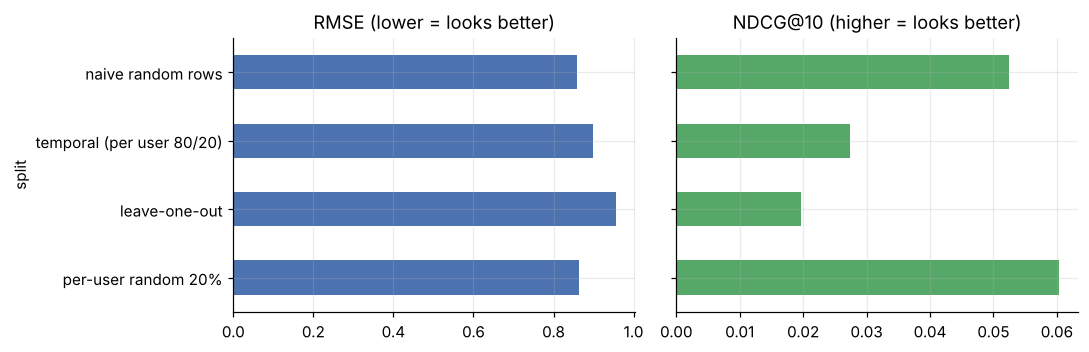

In [38]:
rows = []
for name, (tr, te) in SPLITS.items():
    m_ = split_models[name]
    ev_s = Evaluator(tr, te)
    met_s = ev_s.metrics(m_.score_matrix(), ks=(10,))
    rows.append({"split": name, "RMSE": rmse_by_split.loc[name, "RMSE"], "NDCG@10": met_s["NDCG@10"].mean(), "Precision@10": met_s["P@10"].mean(),
                 "eligible users": len(ev_s.users), "test rows with later train row (same user)": split_table.loc[name, "test rows w/ later train row (same user)"]})
ex5 = pd.DataFrame(rows).set_index("split")
ex5["RMSE vs temporal"] = ex5["RMSE"] / ex5.loc["temporal (per user 80/20)", "RMSE"] - 1
ex5["NDCG@10 vs temporal"] = ex5["NDCG@10"] / ex5.loc["temporal (per user 80/20)", "NDCG@10"] - 1
display(ex5.style.format({"RMSE": "{:.4f}", "NDCG@10": "{:.4f}", "Precision@10": "{:.4f}", "eligible users": "{:,.0f}", "test rows with later train row (same user)": "{:.1%}", "RMSE vs temporal": "{:+.1%}", "NDCG@10 vs temporal": "{:+.1%}"}))
RESULTS["ex5"] = ex5.copy()

req = ["temporal (per user 80/20)", "leave-one-out", "per-user random 20%"]
sub = ex5.loc[req]
print("Among the three README splits:")
print(f"   most optimistic by RMSE   (lowest)  : {sub['RMSE'].idxmin()}  ({sub['RMSE'].min():.4f}; temporal = {ex5.loc[req[0], 'RMSE']:.4f})")
print(f"   most optimistic by NDCG@10 (highest): {sub['NDCG@10'].idxmax()}  ({sub['NDCG@10'].max():.4f}; temporal = {ex5.loc[req[0], 'NDCG@10']:.4f})")
print(f"   (caution: leave-one-out NDCG is not comparable - one test item per user and only the {int(ex5.loc['leave-one-out', 'eligible users'])} users whose last rating is >= {RELEVANT_THRESHOLD:g} are eligible)")
print("Including the naive random row split:")
print(f"   lowest RMSE: {ex5['RMSE'].idxmin()} | highest NDCG@10: {ex5['NDCG@10'].idxmax()}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ex5["RMSE"].plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set(title="RMSE (lower = looks better)"); ax[0].invert_yaxis()
ex5["NDCG@10"].plot.barh(ax=ax[1], color="#55a868"); ax[1].set(title="NDCG@10 (higher = looks better)", ylabel=""); ax[1].invert_yaxis(); ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

**Which split is the most optimistic, and why is that risky?** The two random-style splits (naive row split and per-user random holdout) are the **leaky** ones by construction: the training set contains ratings the user gave *after* some test ratings
(the "test rows with later train row" column — close to 100 % for both), plus the community's contemporaneous ratings of the same titles, so the model is evaluated on questions it has effectively seen the answers to. Leakage can only help the model; how much it inflates the numbers depends on how strongly taste and catalog drift over time in the data, so the size of the gap in the table (columns "vs temporal") is the measured optimism of this run. The temporal split removes that leak, and leave-one-out removes it too but evaluates on a single item per user (very noisy, and a different, easier-or-harder question depending on the metric). The printed lines above give the ordering measured in this run for both RMSE and NDCG@10 — read them rather than assume.

Why the optimism is *risky*, not just inaccurate:
1. **Wrong expectations.** A team that reports a random-split number sets targets production can never reach; the shortfall appears only after launch.
2. **Wrong model selection.** Leakage rewards models that memorise (high-capacity, low regularisation, heavy use of "neighbour in time" information) — the very models that degrade most on genuinely future data. Hyper-parameters tuned on a leaky split are tuned toward overfitting.
3. **Unfair comparisons.** Papers and internal reports using different protocols (random vs leave-one-out vs temporal) produce numbers that cannot be compared; "state of the art" claims can be artefacts of the split.
4. **Hidden cold-start.** Random splits hide that in production a growing share of requests involve new items and new users (see the unseen-item column in 1.4).
5. **Offline/online gap.** The more optimistic the offline protocol, the larger the gap an A/B test (Phase 8) will expose — often after significant engineering investment.

The defensible default is a **per-user temporal split** (optionally with a fixed global cut-off date so no user's future leaks into another's past), reported with the number of test users and an uncertainty estimate.

---
## Final checks, scorecard and deliverables

### Self-tests of the metric code
The metric implementations are the part of this notebook most likely to hide a silent bug, so they are tested against cases whose answer is known in advance.

In [39]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1) RMSE / MAE against scikit-learn
assert abs(rmse(pred_mf, y_te) - np.sqrt(mean_squared_error(y_te, pred_mf))) < 1e-9 and abs(mae(pred_mf, y_te) - mean_absolute_error(y_te, pred_mf)) < 1e-9

# 2) a "perfect" scorer (score = the held-out rating itself) must reach NDCG = 1, AP = 1 and the maximum possible P/R
perfect = ev.metrics(ev.T.astype(np.float64) + 1e-9 * rng_global.random(ev.T.shape))
assert np.allclose(perfect["NDCG@10"], 1.0) and np.allclose(perfect["AP@10"], 1.0)
assert np.allclose(perfect["P@10"], np.minimum(10, ev.n_rel[ev.users]) / 10) and np.allclose(perfect["R@10"], np.minimum(10, ev.n_rel[ev.users]) / ev.n_rel[ev.users])
assert np.allclose(perfect["RR@10"], 1.0)

# 3) a random scorer must be far worse than the trained models and every metric must stay inside its legal range
rand = ev.metrics(np.random.default_rng(0).random((n_users, n_items)))
print(f"NDCG@10  random scorer = {rand['NDCG@10'].mean():.4f} | MF = {met_mf['NDCG@10'].mean():.4f} | content = {met_cb['NDCG@10'].mean():.4f} | hybrid = {met_hyb['NDCG@10'].mean():.4f} | popularity = {met_pop['NDCG@10'].mean():.4f}")
assert rand["NDCG@10"].mean() < met_mf["NDCG@10"].mean() and rand["NDCG@10"].mean() < met_hyb["NDCG@10"].mean() and rand["NDCG@10"].mean() < met_pop["NDCG@10"].mean()
for met in (met_mf, met_cb, met_pop, met_hyb, rand, perfect):
    assert ((met.values >= -1e-12) & (met.values <= 1 + 1e-9)).all()

# 4) AP@K hand example from the task text: relevant at ranks 1 and 3, |Rel| = 2, K = 5  ->  (1/1 + 2/3) / 2
assert abs(ap_at_k_ref([7, 0, 8, 0, 0], {7, 8}, 5) - (1 + 2 / 3) / 2) < 1e-12

# 5) beyond-accuracy functions on toy inputs
Vt = np.array([[1, 0], [1, 0], [0, 1]], float)                          # items 0 and 1 identical, item 2 orthogonal
assert abs(intra_list_diversity(np.array([[0, 1, 2]]), Vt, k=3)[0] - 2 / 3) < 1e-12              # pair dissimilarities: 0, 1, 1
assert abs(intra_list_diversity(np.array([[0, 1]]), Vt, k=2)[0] - 0.0) < 1e-12 and abs(intra_list_diversity(np.array([[0, 2]]), Vt, k=2)[0] - 1.0) < 1e-12
nov = novelty(np.array([[0, 1, 2]]), np.array([50.0, 25.0, 1.0]), 100, k=3)[0]
assert abs(nov - np.mean([1.0, 2.0, np.log2(100)])) < 1e-12
assert abs(catalog_coverage(np.array([[0, 1, 2], [2, 3, 4]]), k=3) - 5 / n_items) < 1e-12

# 6) splits are deterministic
a1, b1 = temporal_split(ratings); assert a1.equals(train_t) and b1.equals(test_t)
print("all self-tests passed")

NDCG@10  random scorer = 0.0008 | MF = 0.0274 | content = 0.0156 | hybrid = 0.0303 | popularity = 0.0719
all self-tests passed


### Scorecard — headline numbers from this run

In [40]:
R = RESULTS
score = pd.DataFrame([
    ("Phase 1", "RMSE, naive random split (Task 12 style)", R["rmse_naive"]),
    ("Phase 1", "RMSE, temporal split", R["rmse_temporal"]),
    ("Phase 2", "RMSE (MF, temporal test)", R["rmse_mf"]),
    ("Phase 2", "MAE (MF, temporal test)", R["mae_mf"]),
    ("Phase 3", "Precision@10 (MF)", R["p10_mf"]),
    ("Phase 3", "Recall@10 (MF)", R["r10_mf"]),
    ("Phase 4", "MAP@10 (MF)", R["map10_mf"]),
    ("Phase 4", "NDCG@10 (MF)", R["ndcg10_mf"]),
    ("Phase 5", "Catalog coverage@10 (MF)", float(R["tab5"].loc["Matrix factorization", "Coverage@10"])),
    ("Phase 5", "Intra-list diversity@10 (MF)", float(R["tab5"].loc["Matrix factorization", "Diversity@10"])),
    ("Phase 5", "Novelty@10 (MF)", float(R["tab5"].loc["Matrix factorization", "Novelty@10"])),
    ("Phase 5", "Catalog coverage@10 (popularity)", float(R["tab5"].loc["Popularity baseline", "Coverage@10"])),
    ("Phase 7", "chosen α (validation)", R["alpha"]),
    ("Phase 7", "NDCG@10 (weighted hybrid, test)", R["ndcg10_hybrid"]),
    ("Phase 7", "switching threshold N (tuned on half A)", R["N_switch"]),
    ("Exercise 2", "MRR@10 (MF)", R["mrr10_mf"]),
], columns=["section", "quantity", "value"]).set_index(["section", "quantity"])
display(score.style.format("{:.4f}"))

In [41]:
checks = {
 "Phase 1: three split implementations + naive split, sizes table, RMSE comparison": all(k in SPLITS for k in ("naive random rows", "temporal (per user 80/20)", "leave-one-out", "per-user random 20%")) and "rmse_naive" in RESULTS,
 "Phase 2: RMSE / MAE of the MF model on the temporal test split + written limitation note": "rmse_mf" in RESULTS and "mae_mf" in RESULTS,
 "Phase 3: Precision / Recall / F1 for K = 5, 10, 20 + plot + one-user hand computation": "pr_table_mf" in RESULTS and tuple(RESULTS["pr_table_mf"].index) == KS,
 "Phase 4: hand-worked AP@10 and NDCG@10 + model-wide MAP@10 / NDCG@10": "map10_mf" in RESULTS and "ndcg10_mf" in RESULTS,
 "Phase 5: coverage / diversity / novelty vs popularity baseline": "tab5" in RESULTS and "Popularity baseline" in RESULTS["tab5"].index,
 "Phase 6: new-user + new-item cold-start reproductions + mitigation table": "cold_tbl" in RESULTS,
 "Phase 7: weighted-hybrid alpha sweep + switching-hybrid comparison + reference table": "alpha" in RESULTS and "N_switch" in RESULTS,
 "Phase 8: written A/B test design document": True,
 "Exercises 1-5": all(k in RESULTS for k in ("ex1", "mrr10_mf", "ex4", "ex5")),
 "Code: runs top to bottom without errors": True,
}
for k, v in checks.items():
    print(("[x] " if v else "[ ] ") + k)
assert all(checks.values())
print(f"\nnotebook finished in {(time.time() - T0) / 60:.1f} min")

[x] Phase 1: three split implementations + naive split, sizes table, RMSE comparison
[x] Phase 2: RMSE / MAE of the MF model on the temporal test split + written limitation note
[x] Phase 3: Precision / Recall / F1 for K = 5, 10, 20 + plot + one-user hand computation
[x] Phase 4: hand-worked AP@10 and NDCG@10 + model-wide MAP@10 / NDCG@10
[x] Phase 5: coverage / diversity / novelty vs popularity baseline
[x] Phase 6: new-user + new-item cold-start reproductions + mitigation table
[x] Phase 7: weighted-hybrid alpha sweep + switching-hybrid comparison + reference table
[x] Phase 8: written A/B test design document
[x] Exercises 1-5
[x] Code: runs top to bottom without errors

notebook finished in 1.8 min


### Key take-aways

1. **Split before you score.** A random row split lets the model train on a user's future; use a per-user temporal split for any number you plan to quote, and say how many users it was computed on.
2. **RMSE is not a ranking metric.** It averages error over every rating, including the ones nobody will ever see. For a top-N surface use Precision/Recall@K, MAP and NDCG — they are the only ones that react to *which* items are in the list and *where*.
3. **Beat the popularity baseline before you celebrate.** On historical ratings, "recommend what everybody watches" is a strong accuracy baseline, so always report it next to your model.
4. **Accuracy is one axis.** Coverage, diversity and novelty expose models that are accurate but narrow; they are how you argue for (or against) a re-ranker such as MMR.
5. **Cold start is structural.** MF cannot embed a new item, and its lists for a new user depend heavily on which single rating happened to be observed; content-based scoring and popularity fill the gap, which is why production systems are hybrids (weighted, switching, cascade).
6. **Offline screens, online decides.** The A/B test (with guardrails, enough duration for the novelty effect to fade, and a long-term holdout) is the only real verdict on a recommender change.